# Guardian 实质政策议题：时间序列图

本 Notebook 使用已经完成的 K=6 政策 LDA 与 DeepSeek 标注结果，不重新训练模型，也不重新调用 API。它分别展示：

1. 主题关注度；
2. 议题情绪；
3. 民主党与共和党态度；
4. 各指数的有效文章数。

默认绘制 `All` 样本，并同时保留原始日频、过去7天滚动和周频版本。可将 `SECTION_GROUP` 改为 `Opinion` 或 `Non-Opinion`，将 `ROLLING_DAYS` 改为 14 获得更平滑的展示。缺失值保留为折线断点，不填成零；橙色点表示有效文章少于 3 篇。指数衡量 Guardian 政策报道样本中呈现的关注度、情绪与态度，不代表全体美国选民。

In [1]:
from pathlib import Path
import json
import math

import pandas as pd
from IPython.display import Image as NotebookImage, Markdown, display

from score_policy_sentiment import draw_panel_series

ROOT = Path.cwd()
if not (ROOT / 'data' / 'policy_sentiment').exists():
    raise FileNotFoundError('请从 Assignment5 项目根目录运行本 Notebook。')

DATA_DIR = ROOT / 'data' / 'policy_sentiment'
FIGURE_DIR = ROOT / 'figures' / 'policy_sentiment' / 'notebook'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SECTION_GROUP = 'All'  # 可改为 'Opinion' 或 'Non-Opinion'
ROLLING_DAYS = 7  # 若希望更平滑，可改为 14

topic_definition = json.loads((ROOT / 'policy_topic_definitions_v1.json').read_text(encoding='utf-8'))
TOPICS = topic_definition['topics']
[(f"T{t['topic_id']}", t['topic_name']) for t in TOPICS]

[('T0', 'AI、数据中心与数字治理'),
 ('T1', '基础设施、公共土地与联邦投资'),
 ('T2', '贸易、公共卫生与法律权利'),
 ('T3', '伊朗战争、石油与能源安全'),
 ('T4', '移民、公共资金与家庭经济'),
 ('T5', '国防开支与军事安全')]

In [2]:
def load_outputs(frequency: str) -> dict[str, pd.DataFrame]:
    if frequency not in {'daily', 'weekly'}:
        raise ValueError("frequency 必须为 'daily' 或 'weekly'")
    files = {
        'attention': DATA_DIR / f'{frequency}_policy_attention.csv',
        'sentiment': DATA_DIR / f'{frequency}_policy_sentiment.csv',
        'party': DATA_DIR / f'{frequency}_policy_party_stance.csv',
    }
    frames = {name: pd.read_csv(path, encoding='utf-8-sig') for name, path in files.items()}
    period_col = 'date' if frequency == 'daily' else 'week_start'
    for frame in frames.values():
        frame[period_col] = pd.to_datetime(frame[period_col])
    return frames

DAILY = load_outputs('daily')
WEEKLY = load_outputs('weekly')

# 输入与范围检查
assert set(DAILY['attention']['section_group']) == {'All', 'Opinion', 'Non-Opinion'}
assert set(WEEKLY['attention']['section_group']) == {'All', 'Opinion', 'Non-Opinion'}
assert DAILY['attention'].query("section_group == 'All'")['date'].nunique() == 92
assert WEEKLY['attention'].query("section_group == 'All'")['week_start'].nunique() == 14
assert DAILY['attention']['attention_share'].dropna().between(0, 1).all()
assert DAILY['sentiment']['topic_sentiment_index'].dropna().between(-1, 1).all()
assert DAILY['party']['democrat_stance_index'].dropna().between(-1, 1).all()
assert DAILY['party']['republican_stance_index'].dropna().between(-1, 1).all()
print('输入检查通过：日频 92 天，周频 14 周，三个 section_group 均齐全。')

输入检查通过：日频 92 天，周频 14 周，三个 section_group 均齐全。


In [3]:
def coverage_table(frames: dict[str, pd.DataFrame], frequency: str, section_group: str) -> pd.DataFrame:
    rows = []
    for topic in TOPICS:
        topic_id = topic['topic_id']
        s = frames['sentiment'].query('section_group == @section_group and topic_id == @topic_id')
        p = frames['party'].query('section_group == @section_group and topic_id == @topic_id')
        rows.append({
            'topic': f"T{topic_id} {topic['topic_name']}",
            'periods': len(s),
            'sentiment_periods_with_value': int(s['topic_sentiment_index'].notna().sum()),
            'mean_sentiment_effective_articles': s['effective_articles'].mean(),
            'democrat_periods_with_value': int(p['democrat_stance_index'].notna().sum()),
            'republican_periods_with_value': int(p['republican_stance_index'].notna().sum()),
        })
    return pd.DataFrame(rows)

display(Markdown(f'### 当前绘图分组：`{SECTION_GROUP}`'))
display(coverage_table(DAILY, 'daily', SECTION_GROUP).round(2))

### 当前绘图分组：`All`

,topic,periods,sentiment_periods_with_value,mean_sentiment_effective_articles,democrat_periods_with_value,republican_periods_with_value
0,T0 AI、数据中心与数字治理,92,24,0.37,11,12
1,T1 基础设施、公共土地与联邦投资,92,30,0.37,14,19
2,T2 贸易、公共卫生与法律权利,92,74,1.73,48,63
3,T3 伊朗战争、石油与能源安全,92,56,1.24,16,40
4,T4 移民、公共资金与家庭经济,92,62,1.33,35,47
5,T5 国防开支与军事安全,92,56,1.01,22,38


In [4]:
def _values(series: pd.Series) -> list[float | None]:
    return [None if pd.isna(value) else float(value) for value in series]

def _flags(series: pd.Series) -> list[bool]:
    return series.fillna(True).astype(bool).tolist()

def build_rolling_outputs(daily_frames: dict[str, pd.DataFrame], window_days: int = 7) -> dict[str, pd.DataFrame]:
    keys = ['section_group', 'topic_id']

    def rolling_sum(frame: pd.DataFrame, column: str) -> pd.Series:
        return frame.groupby(keys, sort=False)[column].transform(
            lambda values: values.rolling(window_days, min_periods=1).sum()
        )

    attention = daily_frames['attention'].sort_values(keys + ['date']).copy()
    attention['article_count'] = rolling_sum(attention, 'article_count')
    attention['topic_probability_sum'] = rolling_sum(attention, 'topic_probability_sum')
    attention['attention_share'] = attention['topic_probability_sum'].div(
        attention['article_count'].where(attention['article_count'].gt(0))
    ).clip(0, 1)
    attention['low_sample'] = attention['article_count'].lt(3)

    sentiment = daily_frames['sentiment'].sort_values(keys + ['date']).copy()
    sentiment['_numerator'] = sentiment['topic_sentiment_index'].fillna(0) * sentiment['effective_weight']
    sentiment['effective_articles'] = rolling_sum(sentiment, 'effective_articles')
    sentiment['effective_weight'] = rolling_sum(sentiment, 'effective_weight')
    sentiment['_numerator'] = rolling_sum(sentiment, '_numerator')
    sentiment['topic_sentiment_index'] = sentiment['_numerator'].div(
        sentiment['effective_weight'].where(sentiment['effective_weight'].gt(0))
    ).clip(-1, 1)
    sentiment['low_sample'] = sentiment['effective_articles'].lt(3)
    sentiment = sentiment.drop(columns='_numerator')

    party = daily_frames['party'].sort_values(keys + ['date']).copy()
    for party_name in ('democrat', 'republican'):
        index_col = f'{party_name}_stance_index'
        article_col = f'{party_name}_effective_articles'
        weight_col = f'{party_name}_effective_weight'
        numerator_col = f'_{party_name}_numerator'
        party[numerator_col] = party[index_col].fillna(0) * party[weight_col]
        party[article_col] = rolling_sum(party, article_col)
        party[weight_col] = rolling_sum(party, weight_col)
        party[numerator_col] = rolling_sum(party, numerator_col)
        party[index_col] = party[numerator_col].div(party[weight_col].where(party[weight_col].gt(0))).clip(-1, 1)
        party[f'{party_name}_low_sample'] = party[article_col].lt(3)
        party = party.drop(columns=numerator_col)

    return {'attention': attention, 'sentiment': sentiment, 'party': party}

ROLLING = build_rolling_outputs(DAILY, ROLLING_DAYS)
for metric, frame in ROLLING.items():
    frame.to_csv(DATA_DIR / f'rolling_{ROLLING_DAYS}d_policy_{metric}.csv', index=False, encoding='utf-8-sig')

def draw_time_series(frequency: str, section_group: str = 'All') -> dict[str, Path]:
    frame_options = {'daily': DAILY, 'rolling': ROLLING, 'weekly': WEEKLY}
    if frequency not in frame_options:
        raise ValueError("frequency 必须为 'daily'、'rolling' 或 'weekly'")
    frames = frame_options[frequency]
    period_col = 'week_start' if frequency == 'weekly' else 'date'
    filtered = {
        name: frame.loc[frame['section_group'].eq(section_group)].copy()
        for name, frame in frames.items()
    }
    periods = sorted(filtered['attention'][period_col].drop_duplicates())
    labels = [period.strftime('%Y-%m-%d') for period in periods]

    attention_series, sentiment_series, party_series, sample_series = {}, {}, {}, {}
    attention_low, sentiment_low, party_low, sample_low = {}, {}, {}, {}
    max_sample = 1

    for topic in TOPICS:
        topic_id = topic['topic_id']
        a = filtered['attention'].loc[filtered['attention']['topic_id'].eq(topic_id)].set_index(period_col).reindex(periods)
        s = filtered['sentiment'].loc[filtered['sentiment']['topic_id'].eq(topic_id)].set_index(period_col).reindex(periods)
        p = filtered['party'].loc[filtered['party']['topic_id'].eq(topic_id)].set_index(period_col).reindex(periods)

        attention_series[topic_id] = [('Attention', _values(a['attention_share']), '#24527A')]
        sentiment_series[topic_id] = [('Topic sentiment', _values(s['topic_sentiment_index']), '#24527A')]
        party_series[topic_id] = [
            ('Democrat', _values(p['democrat_stance_index']), '#2878B5'),
            ('Republican', _values(p['republican_stance_index']), '#C44E52'),
        ]
        sample_series[topic_id] = [
            ('Sent N', _values(s['effective_articles']), '#24527A'),
            ('Dem N', _values(p['democrat_effective_articles']), '#2878B5'),
            ('Rep N', _values(p['republican_effective_articles']), '#C44E52'),
        ]

        attention_low[topic_id] = _flags(a['low_sample'])
        sentiment_low[topic_id] = _flags(s['low_sample'])
        party_low[topic_id] = _flags(p['democrat_low_sample'] | p['republican_low_sample'])
        sample_low[topic_id] = _flags(s['low_sample'])
        max_sample = max(
            max_sample,
            int(s['effective_articles'].max() or 0),
            int(p['democrat_effective_articles'].max() or 0),
            int(p['republican_effective_articles'].max() or 0),
        )

    frequency_label = {'daily': 'Daily', 'rolling': f'Trailing {ROLLING_DAYS}-day', 'weekly': 'Weekly'}[frequency]
    file_prefix = f'rolling_{ROLLING_DAYS}d' if frequency == 'rolling' else frequency
    safe_group = section_group.lower().replace('-', '_').replace(' ', '_')
    output_paths = {
        'attention': FIGURE_DIR / f'{file_prefix}_{safe_group}_policy_attention.png',
        'sentiment': FIGURE_DIR / f'{file_prefix}_{safe_group}_policy_sentiment.png',
        'party': FIGURE_DIR / f'{file_prefix}_{safe_group}_policy_party_stance.png',
        'sample': FIGURE_DIR / f'{file_prefix}_{safe_group}_effective_sample_size.png',
    }

    draw_panel_series(output_paths['attention'], f'Guardian policy-topic attention ({frequency_label}, {section_group})', TOPICS, labels,
                      attention_series, attention_low, 'Orange points: fewer than 3 articles. Missing periods are not filled with zero.', 0, 1)
    draw_panel_series(output_paths['sentiment'], f'Guardian policy-topic sentiment presented in text ({frequency_label}, {section_group})', TOPICS, labels,
                      sentiment_series, sentiment_low, 'Range -1 to +1. Orange points: fewer than 3 effective articles; gaps are missing.', -1, 1)
    draw_panel_series(output_paths['party'], f'Topic-specific party stance presented in Guardian text ({frequency_label}, {section_group})', TOPICS, labels,
                      party_series, party_low, 'Party series use separate covered samples and must not be directly subtracted.', -1, 1)
    draw_panel_series(output_paths['sample'], f'Effective article counts behind each index ({frequency_label}, {section_group})', TOPICS, labels,
                      sample_series, sample_low, 'Counts are shown separately because sentiment and party indices use different denominators.', 0, float(max_sample))
    return output_paths

def show_outputs(paths: dict[str, Path]) -> None:
    for label, path in paths.items():
        display(Markdown(f'### {label.title()}'))
        display(NotebookImage(filename=str(path), width=1200))

## 日频时间序列

日频覆盖纽约当地日期 2026-07-10 至 2026-10-09。10 月 9 日没有政策主样本文章，因此保持缺失。

### Attention

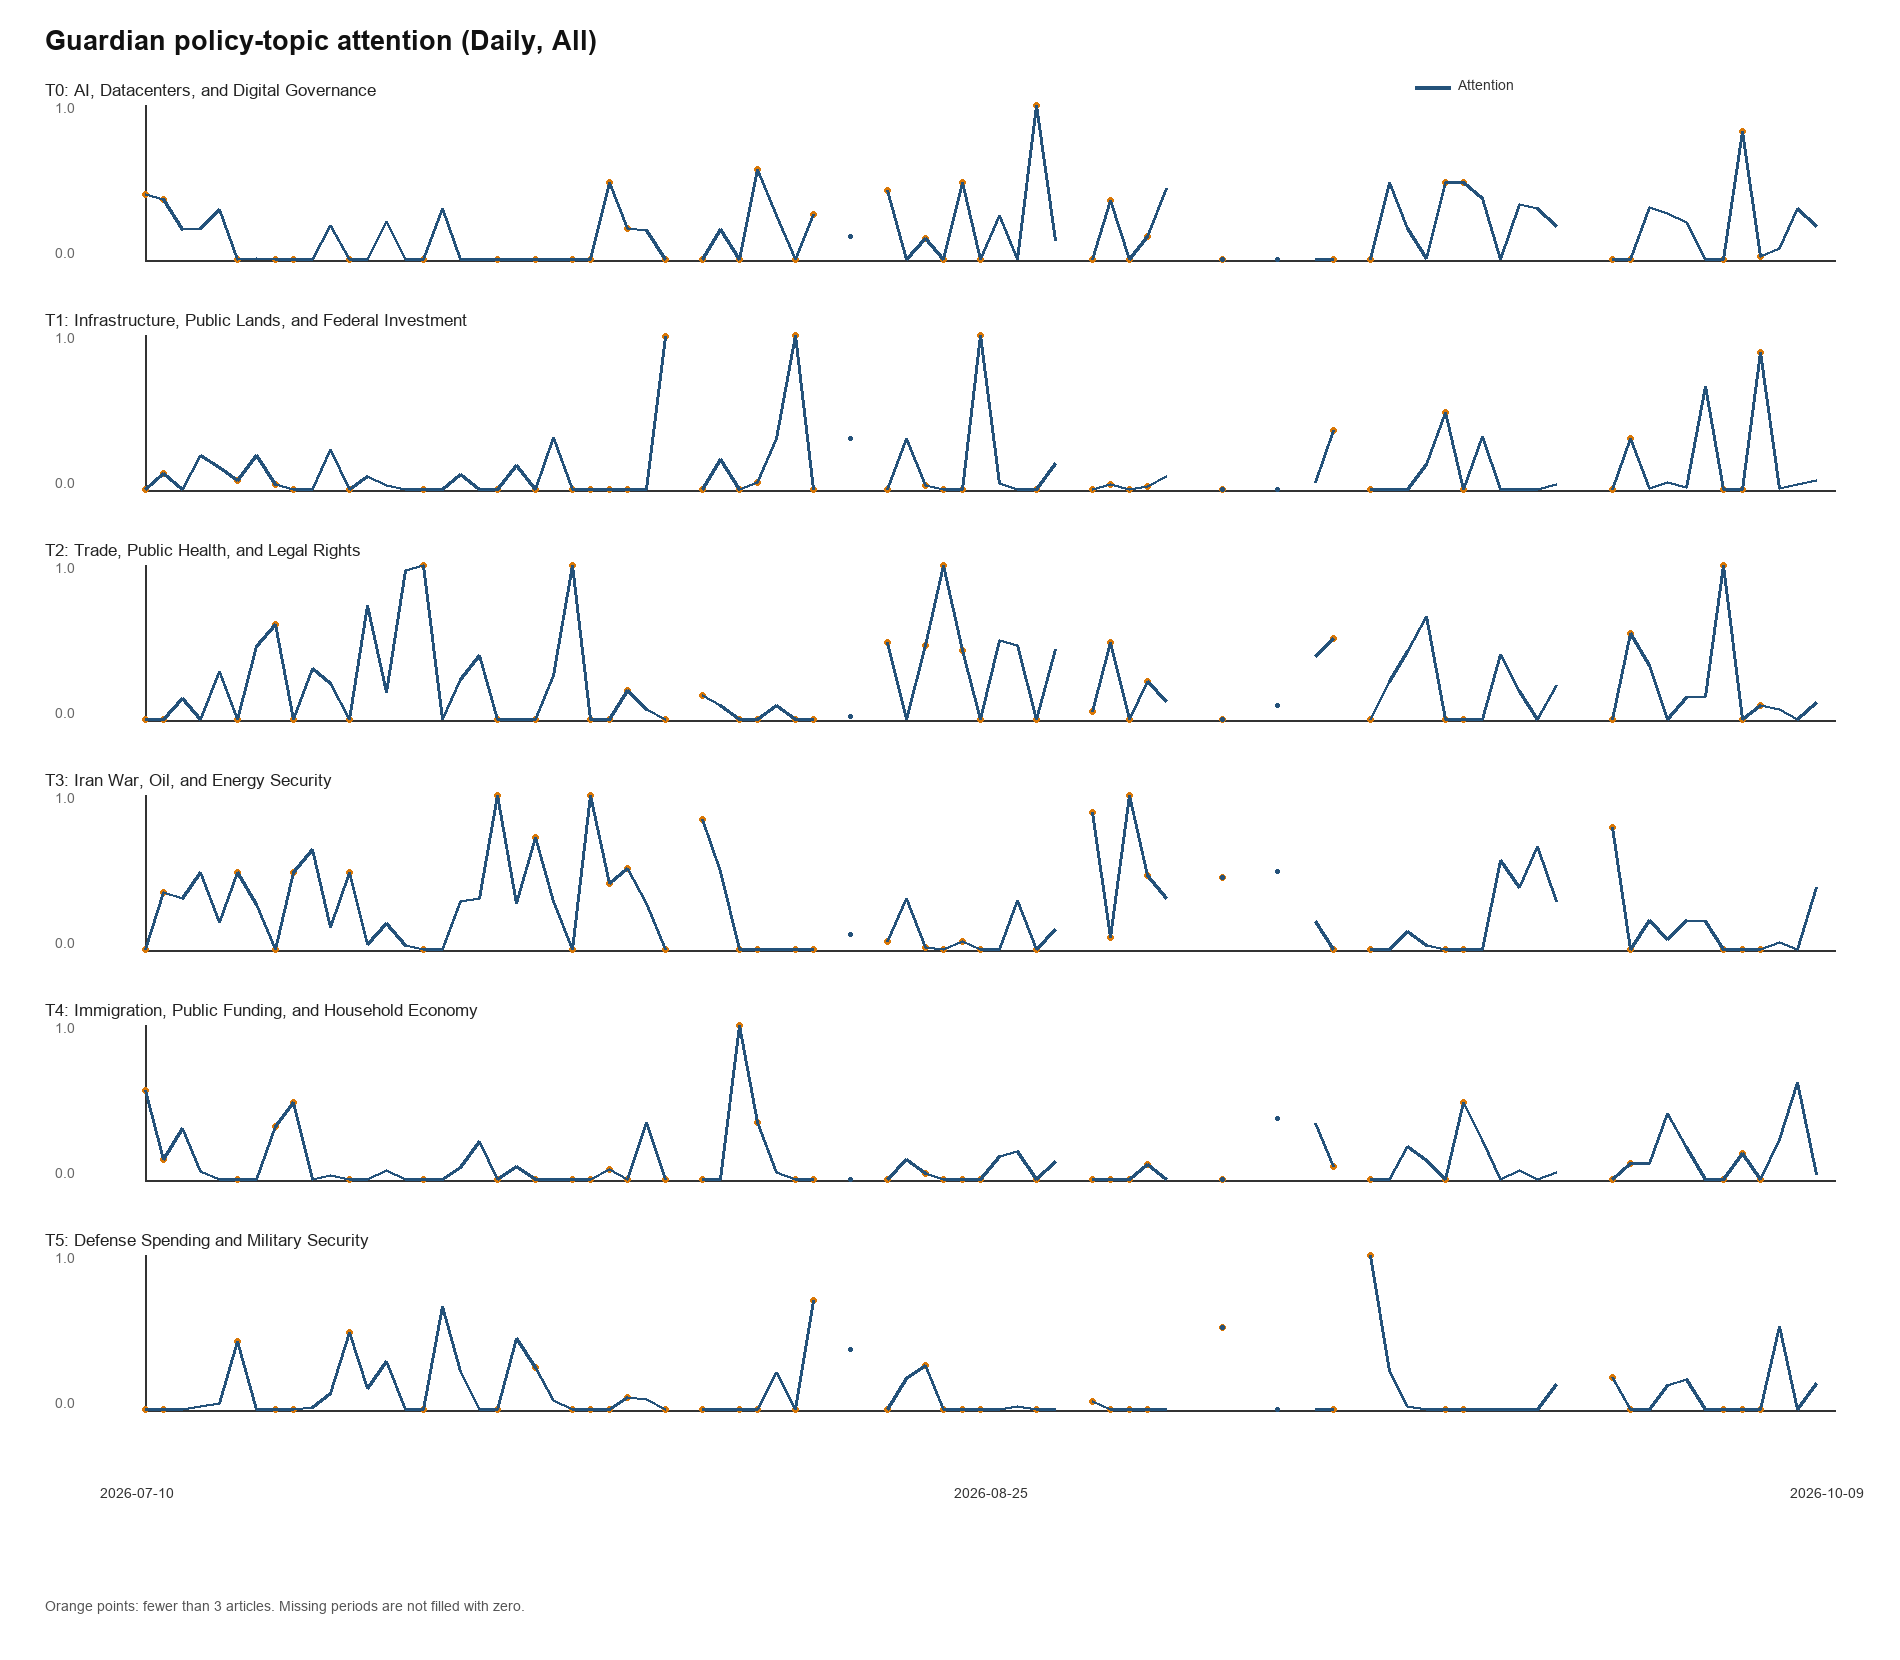

### Sentiment

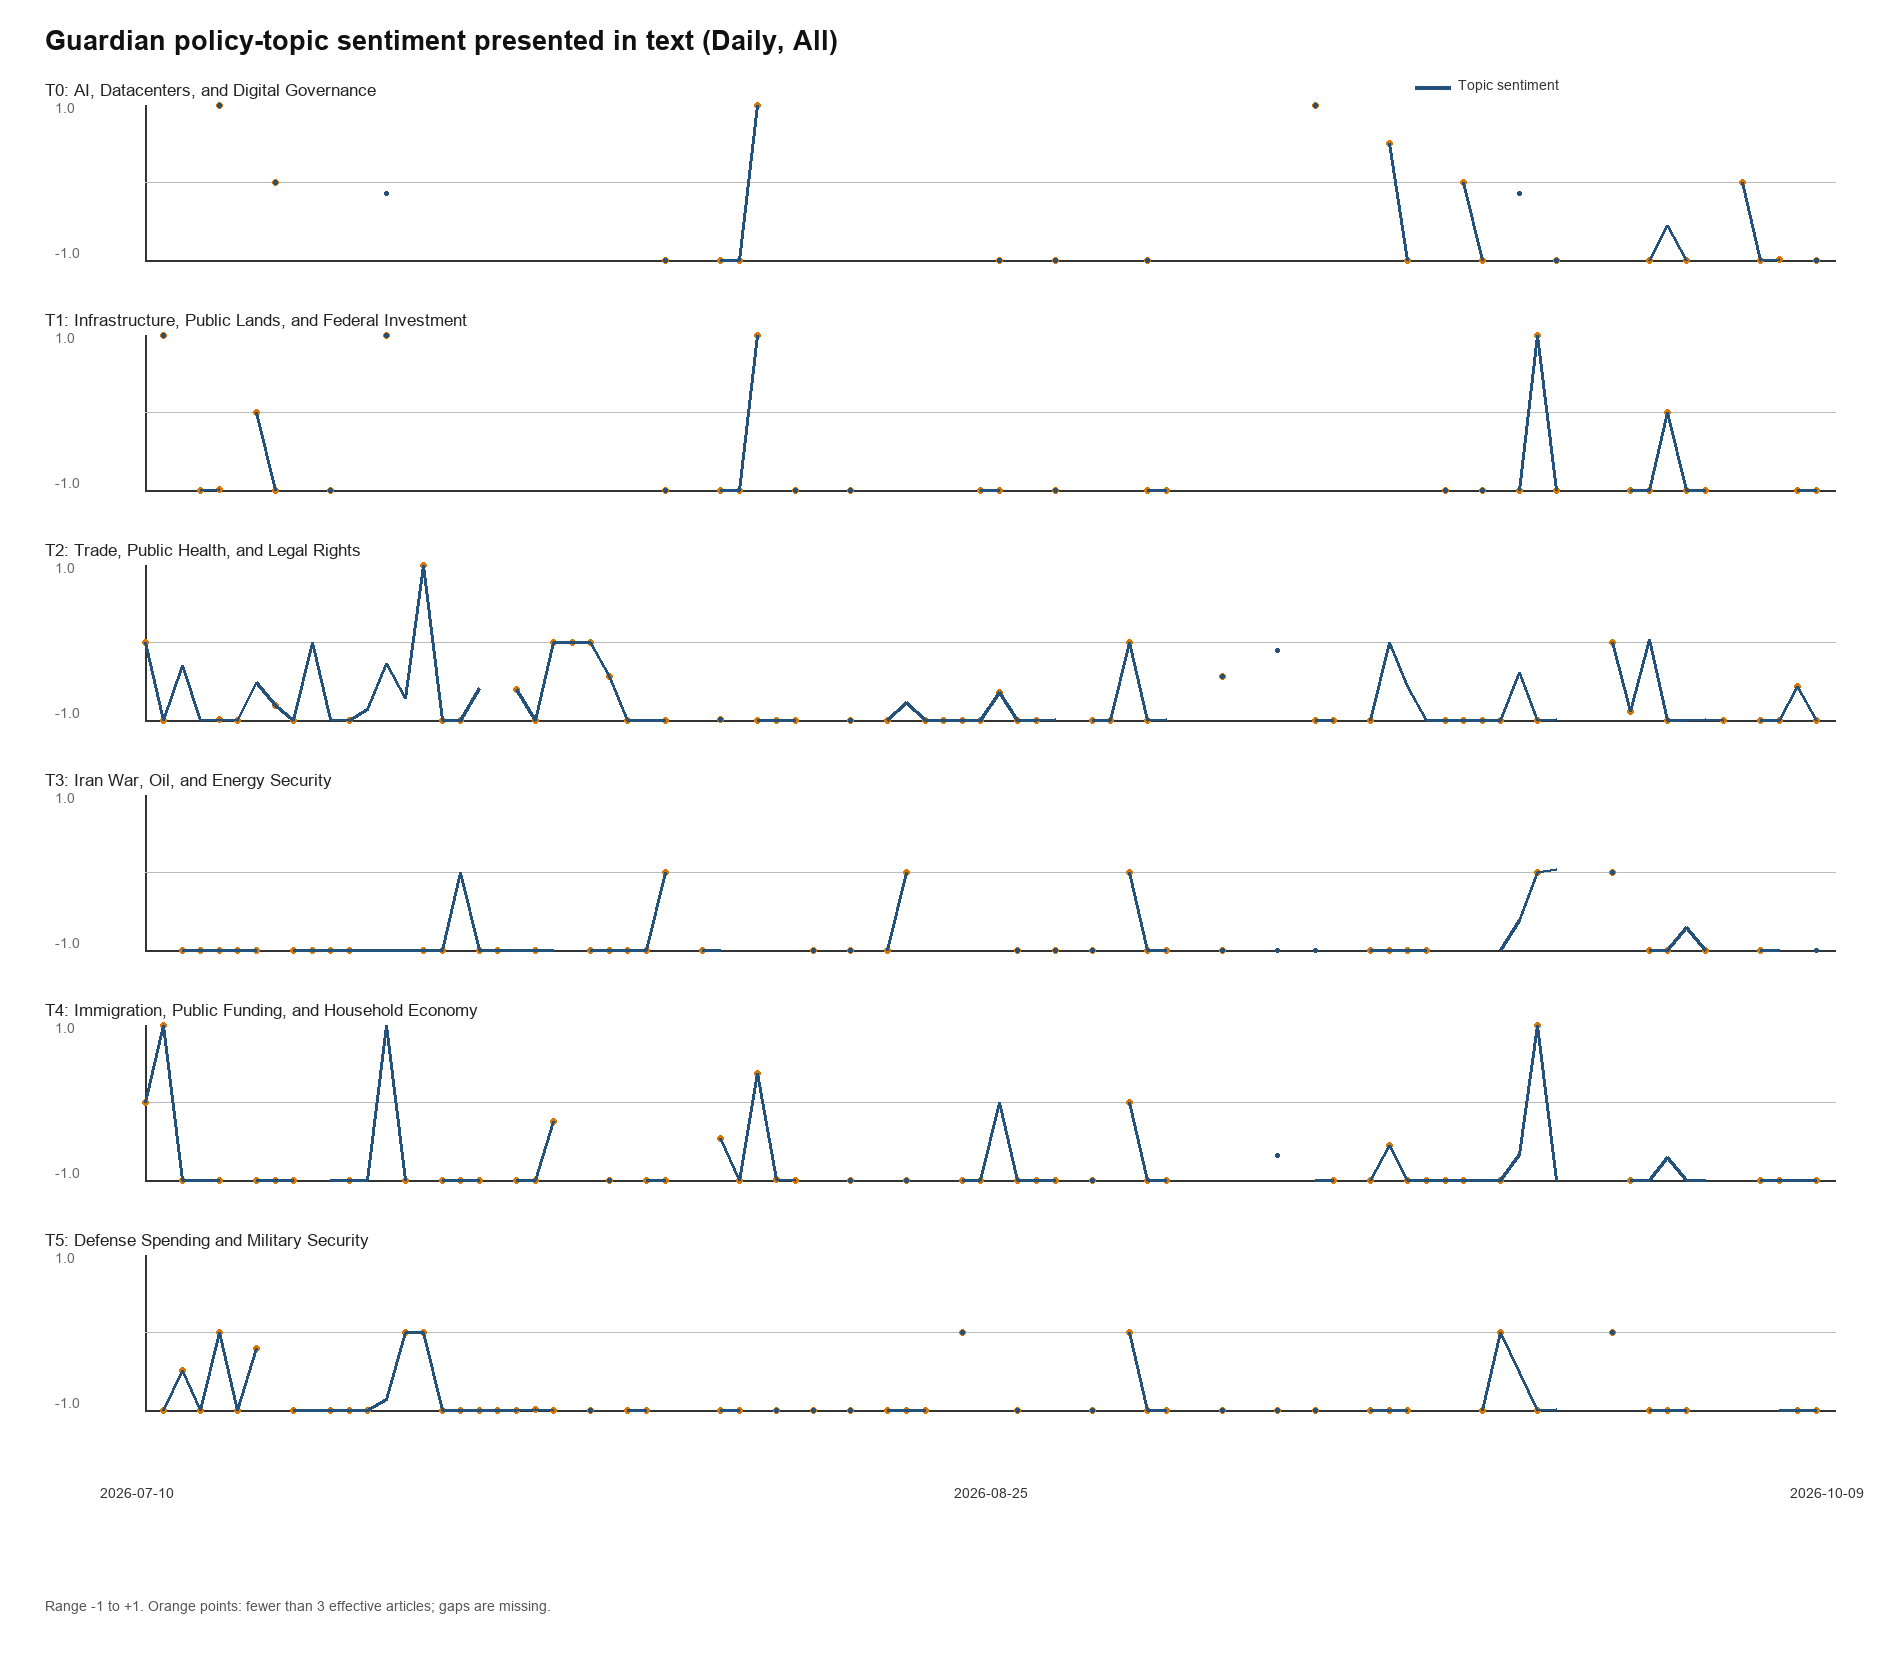

### Party

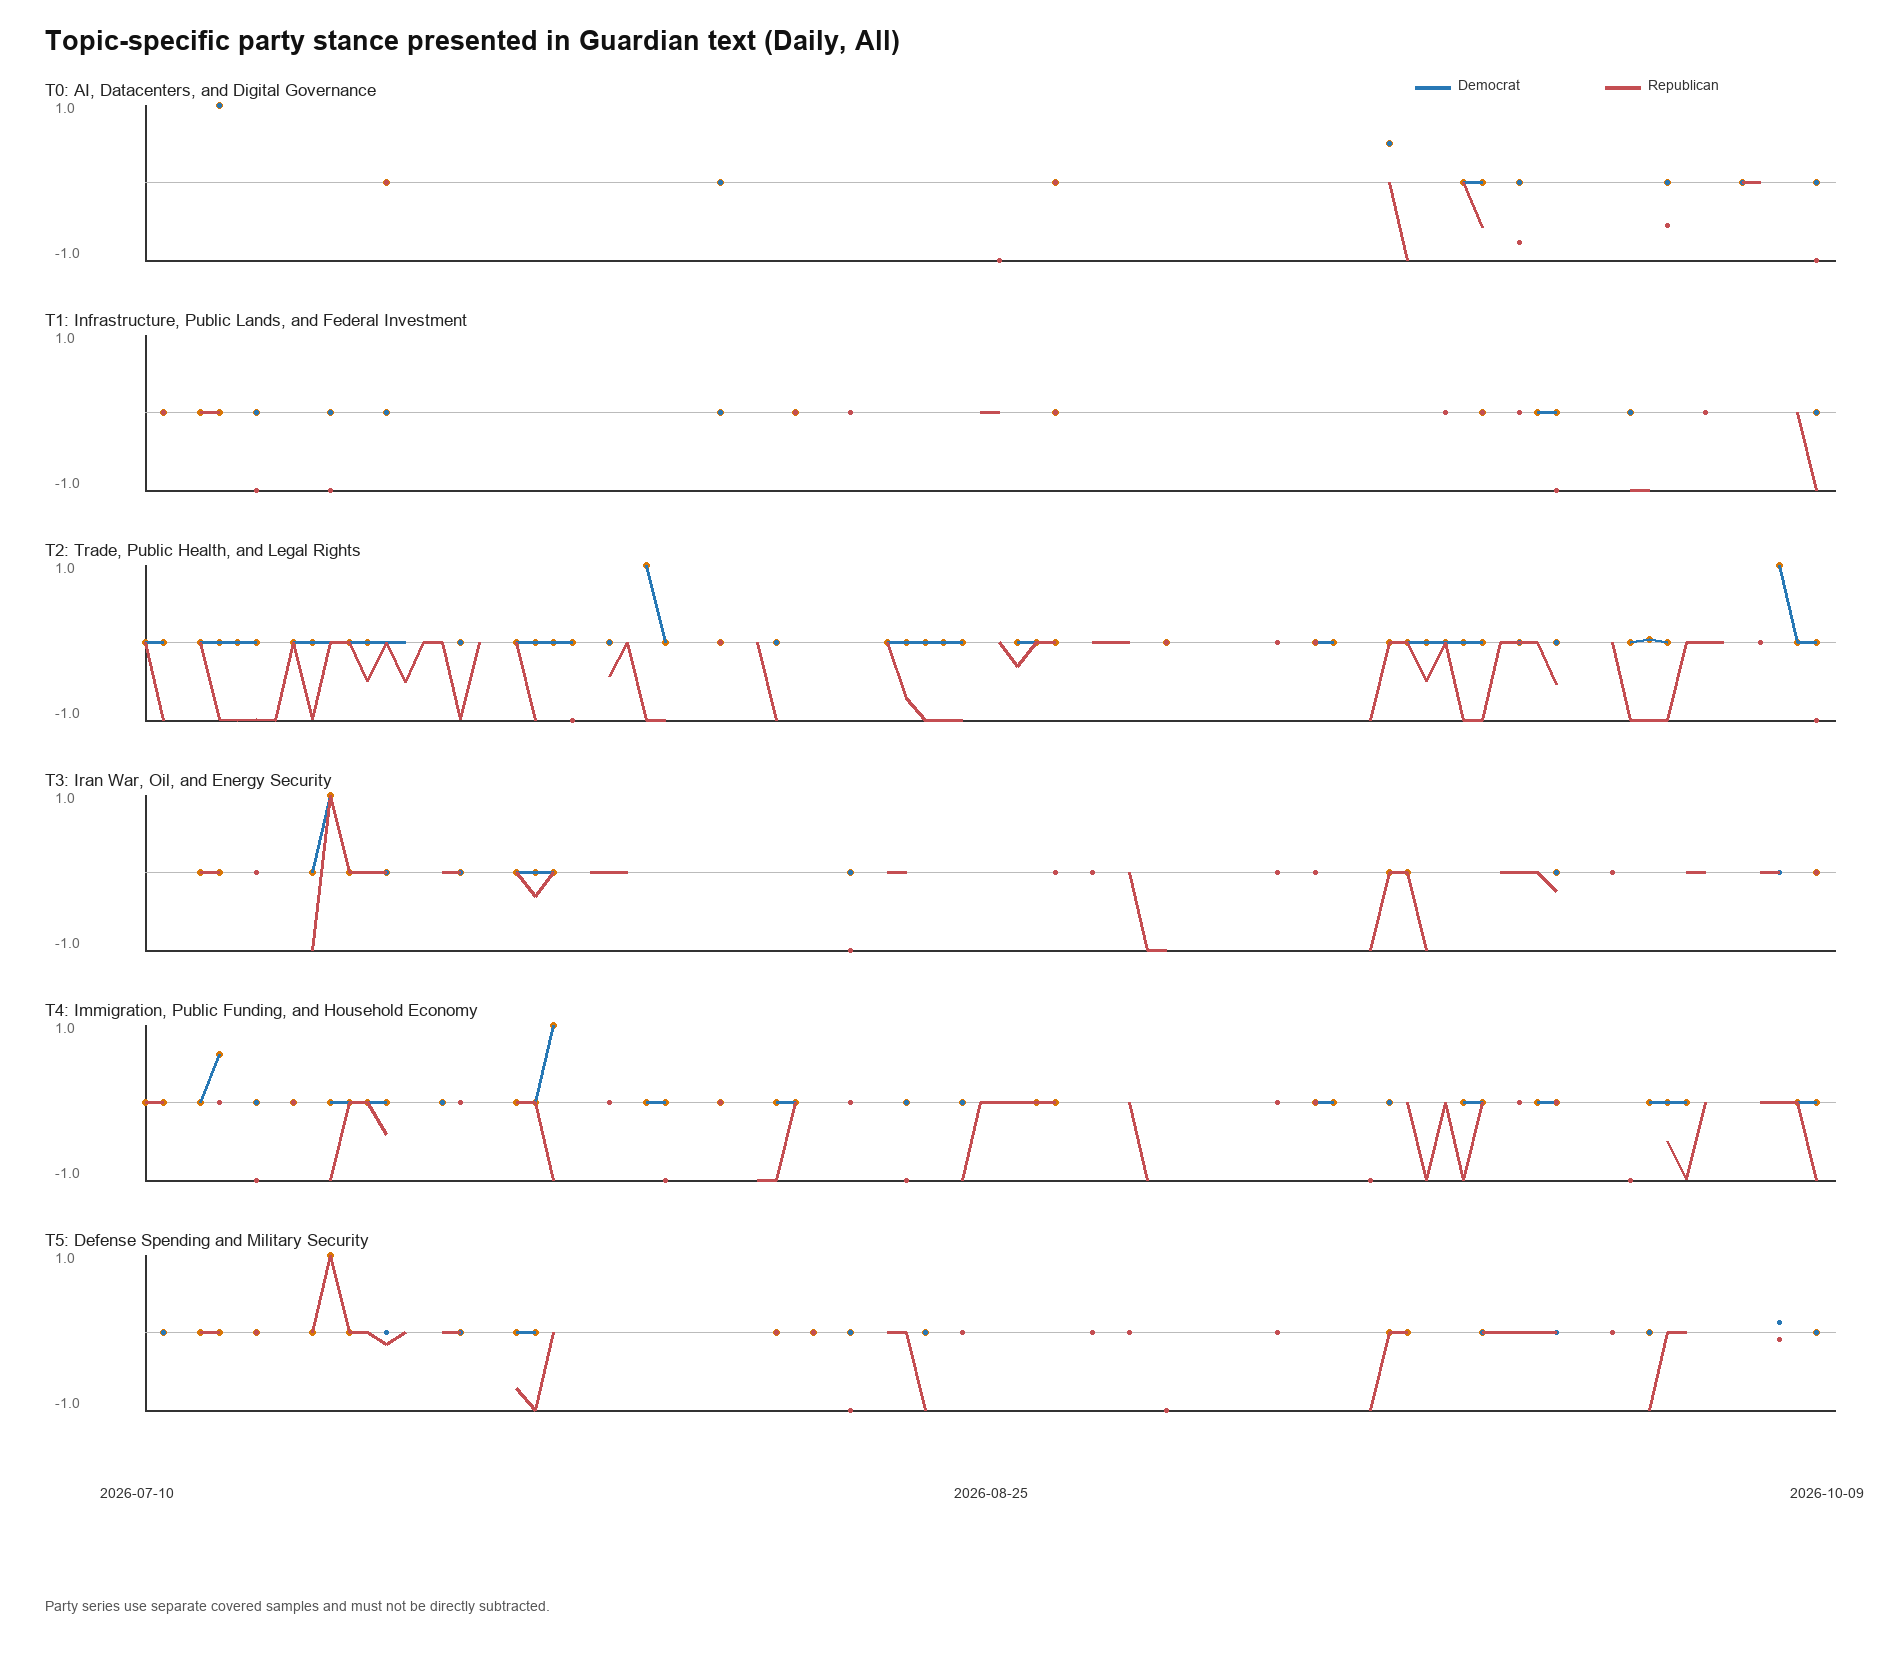

### Sample

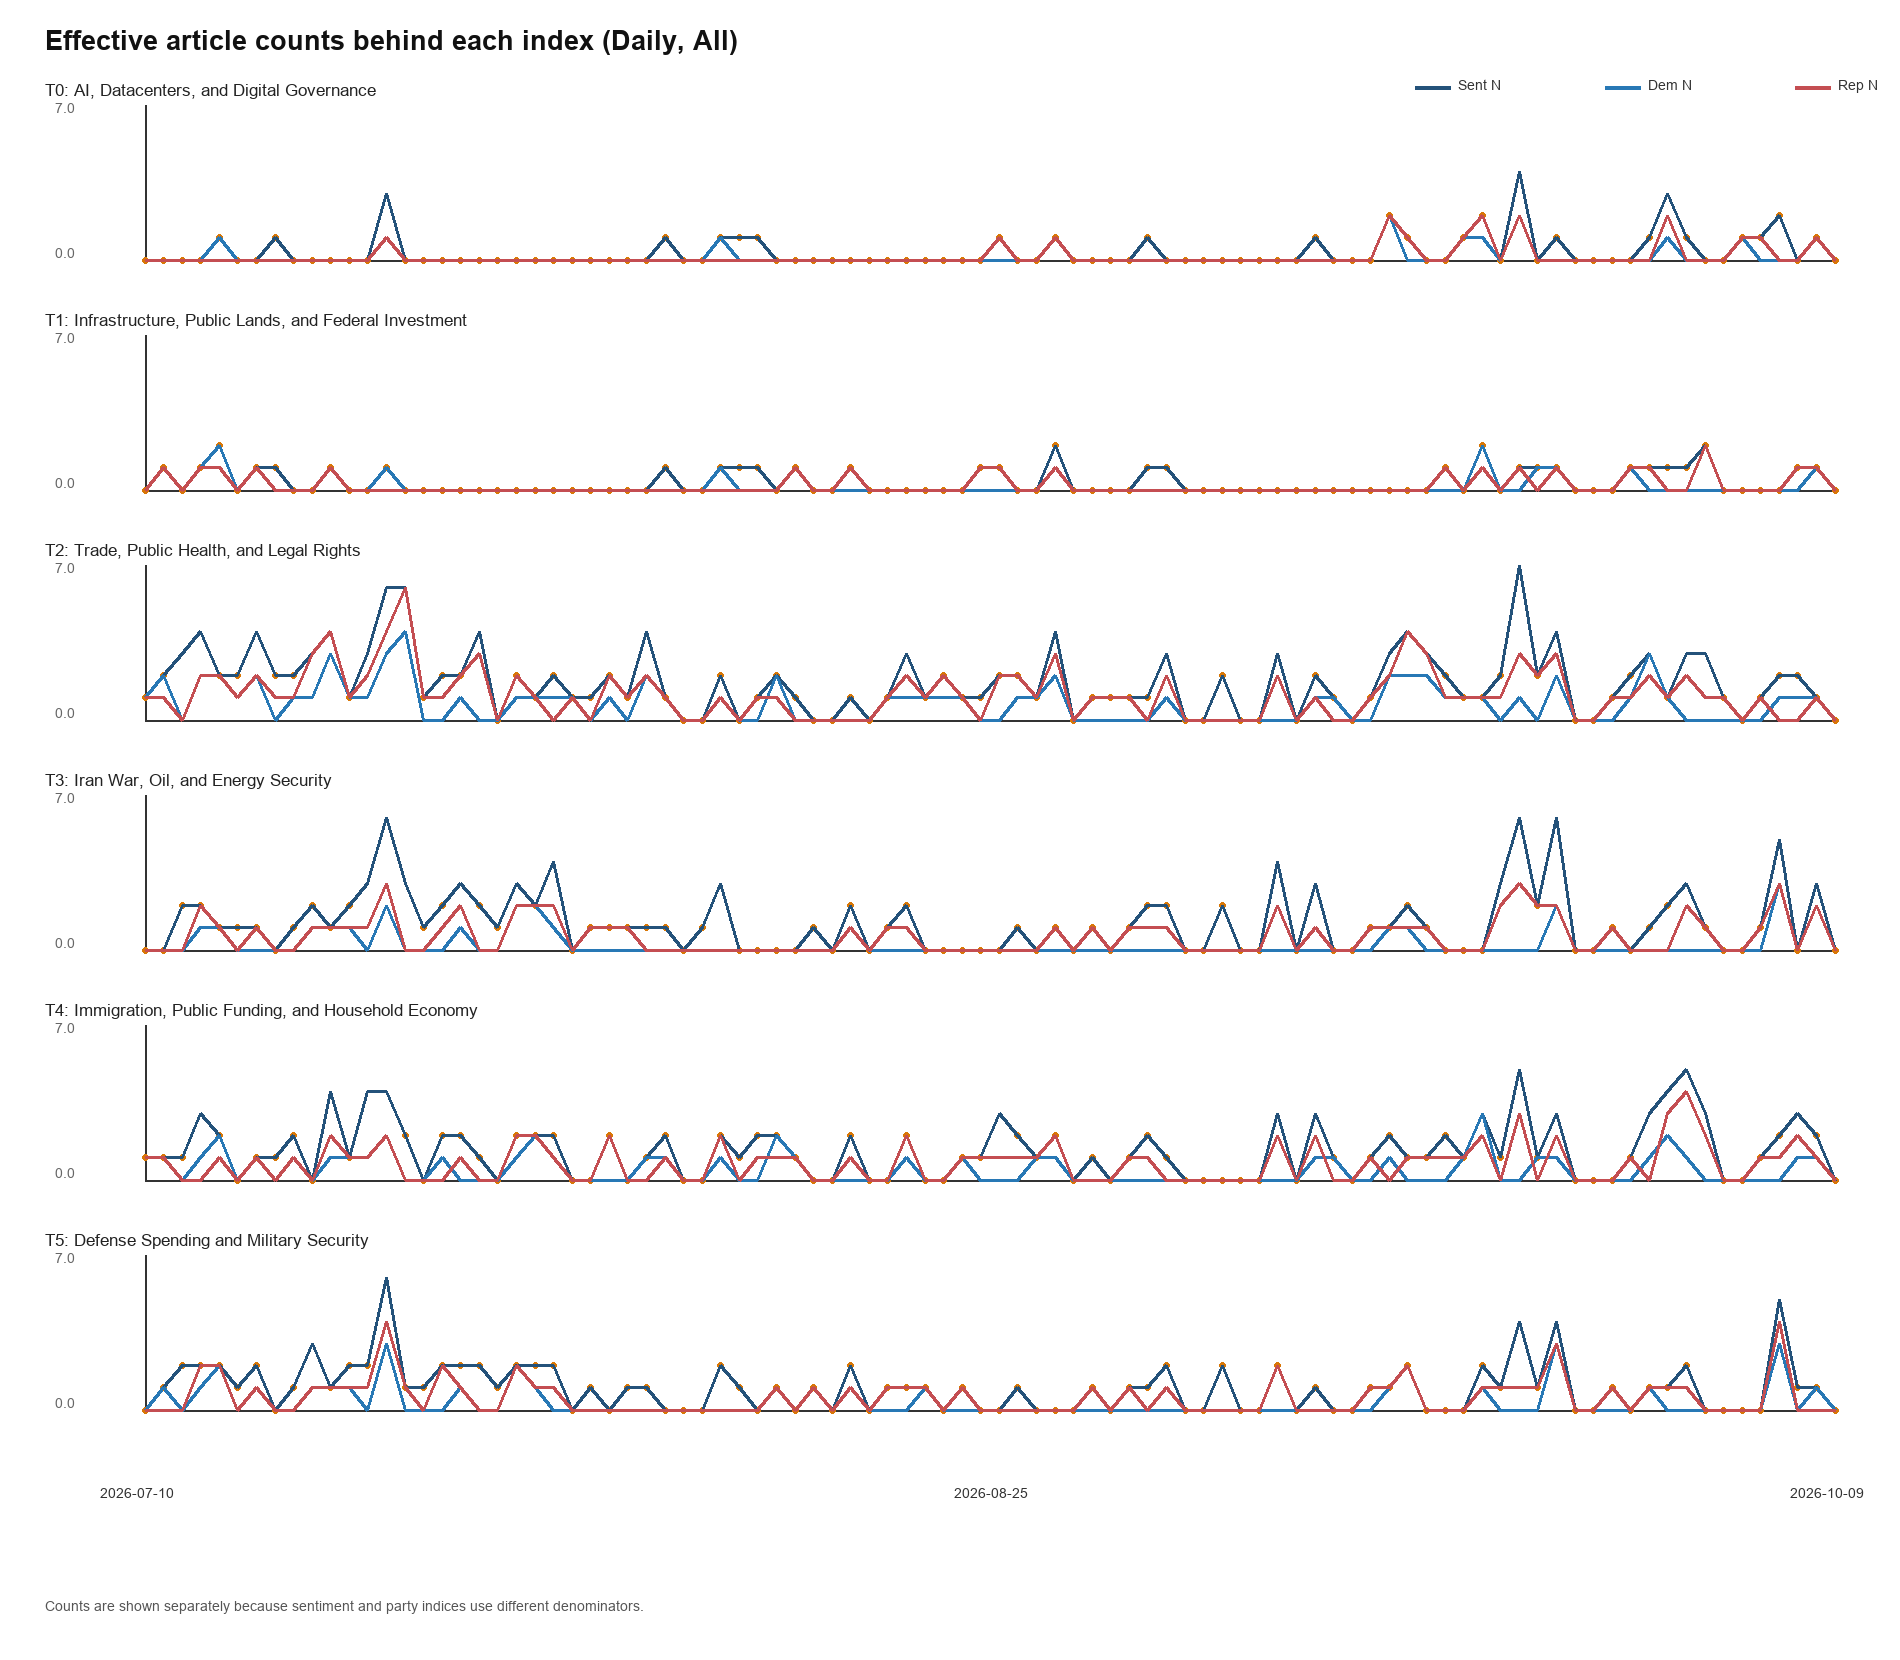

In [5]:
daily_paths = draw_time_series('daily', SECTION_GROUP)
show_outputs(daily_paths)

## 过去7天滚动时间序列

每个日期使用当日及前6个纽约当地日的文章直接重新加权。关注度使用窗口内主题概率总和除以文章数；情绪和两党态度分别使用窗口内概率加权分子与各自有效权重重新计算。这里没有插值，也没有把缺失值填成零。首6天使用可获得的不完整窗口。

### Attention

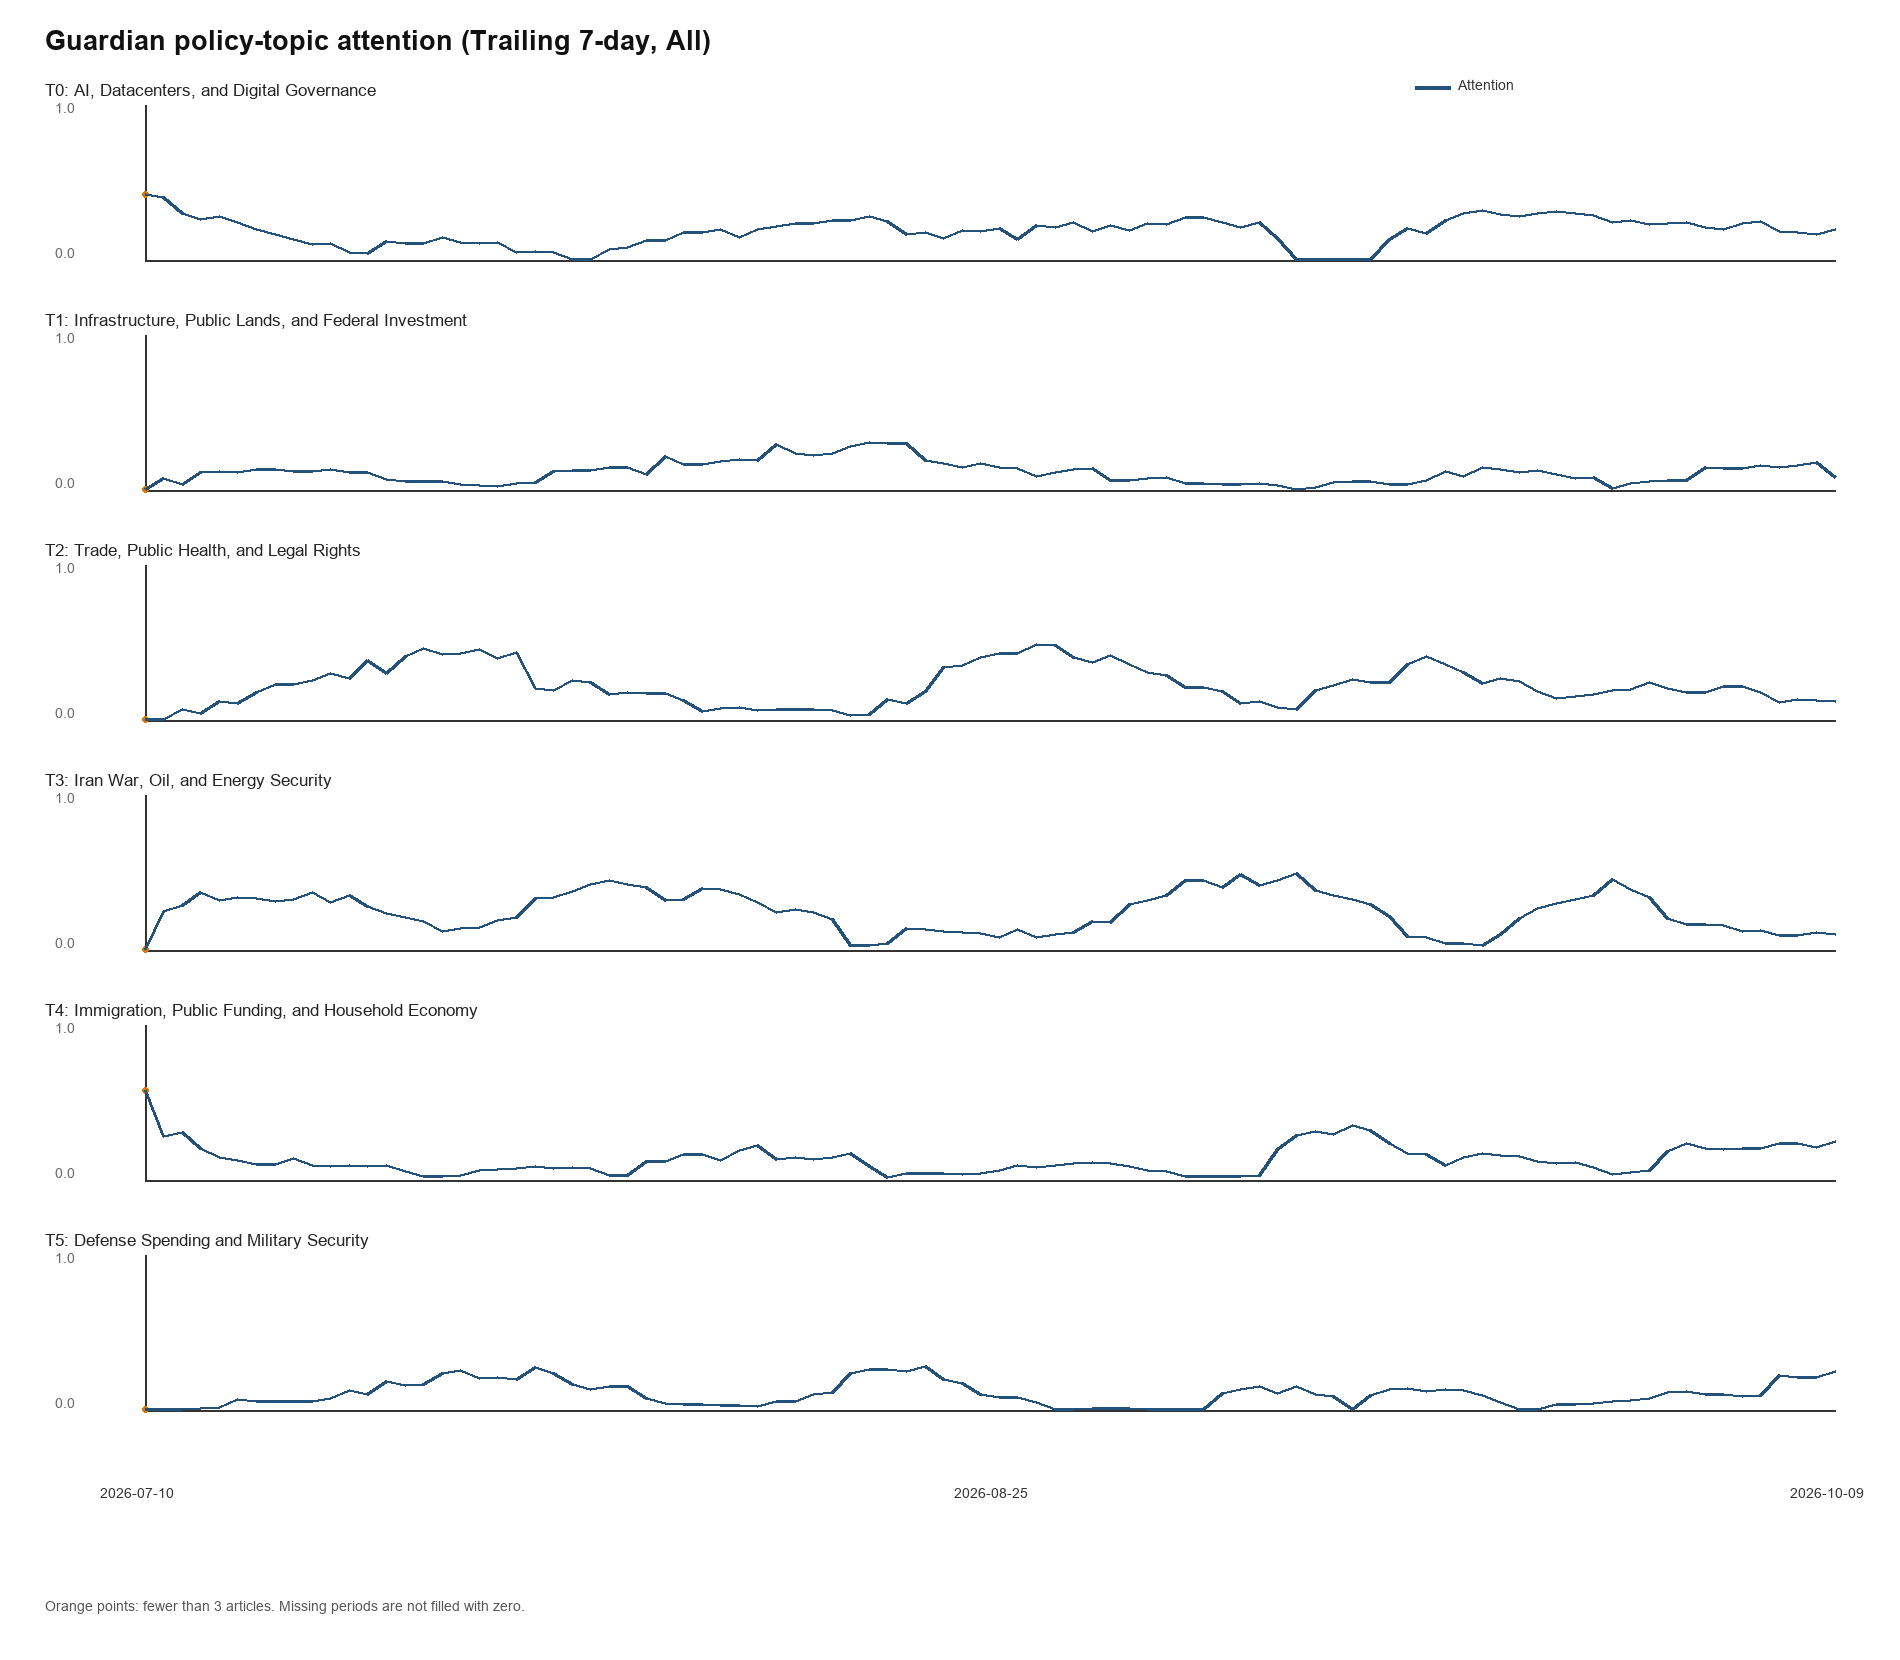

### Sentiment

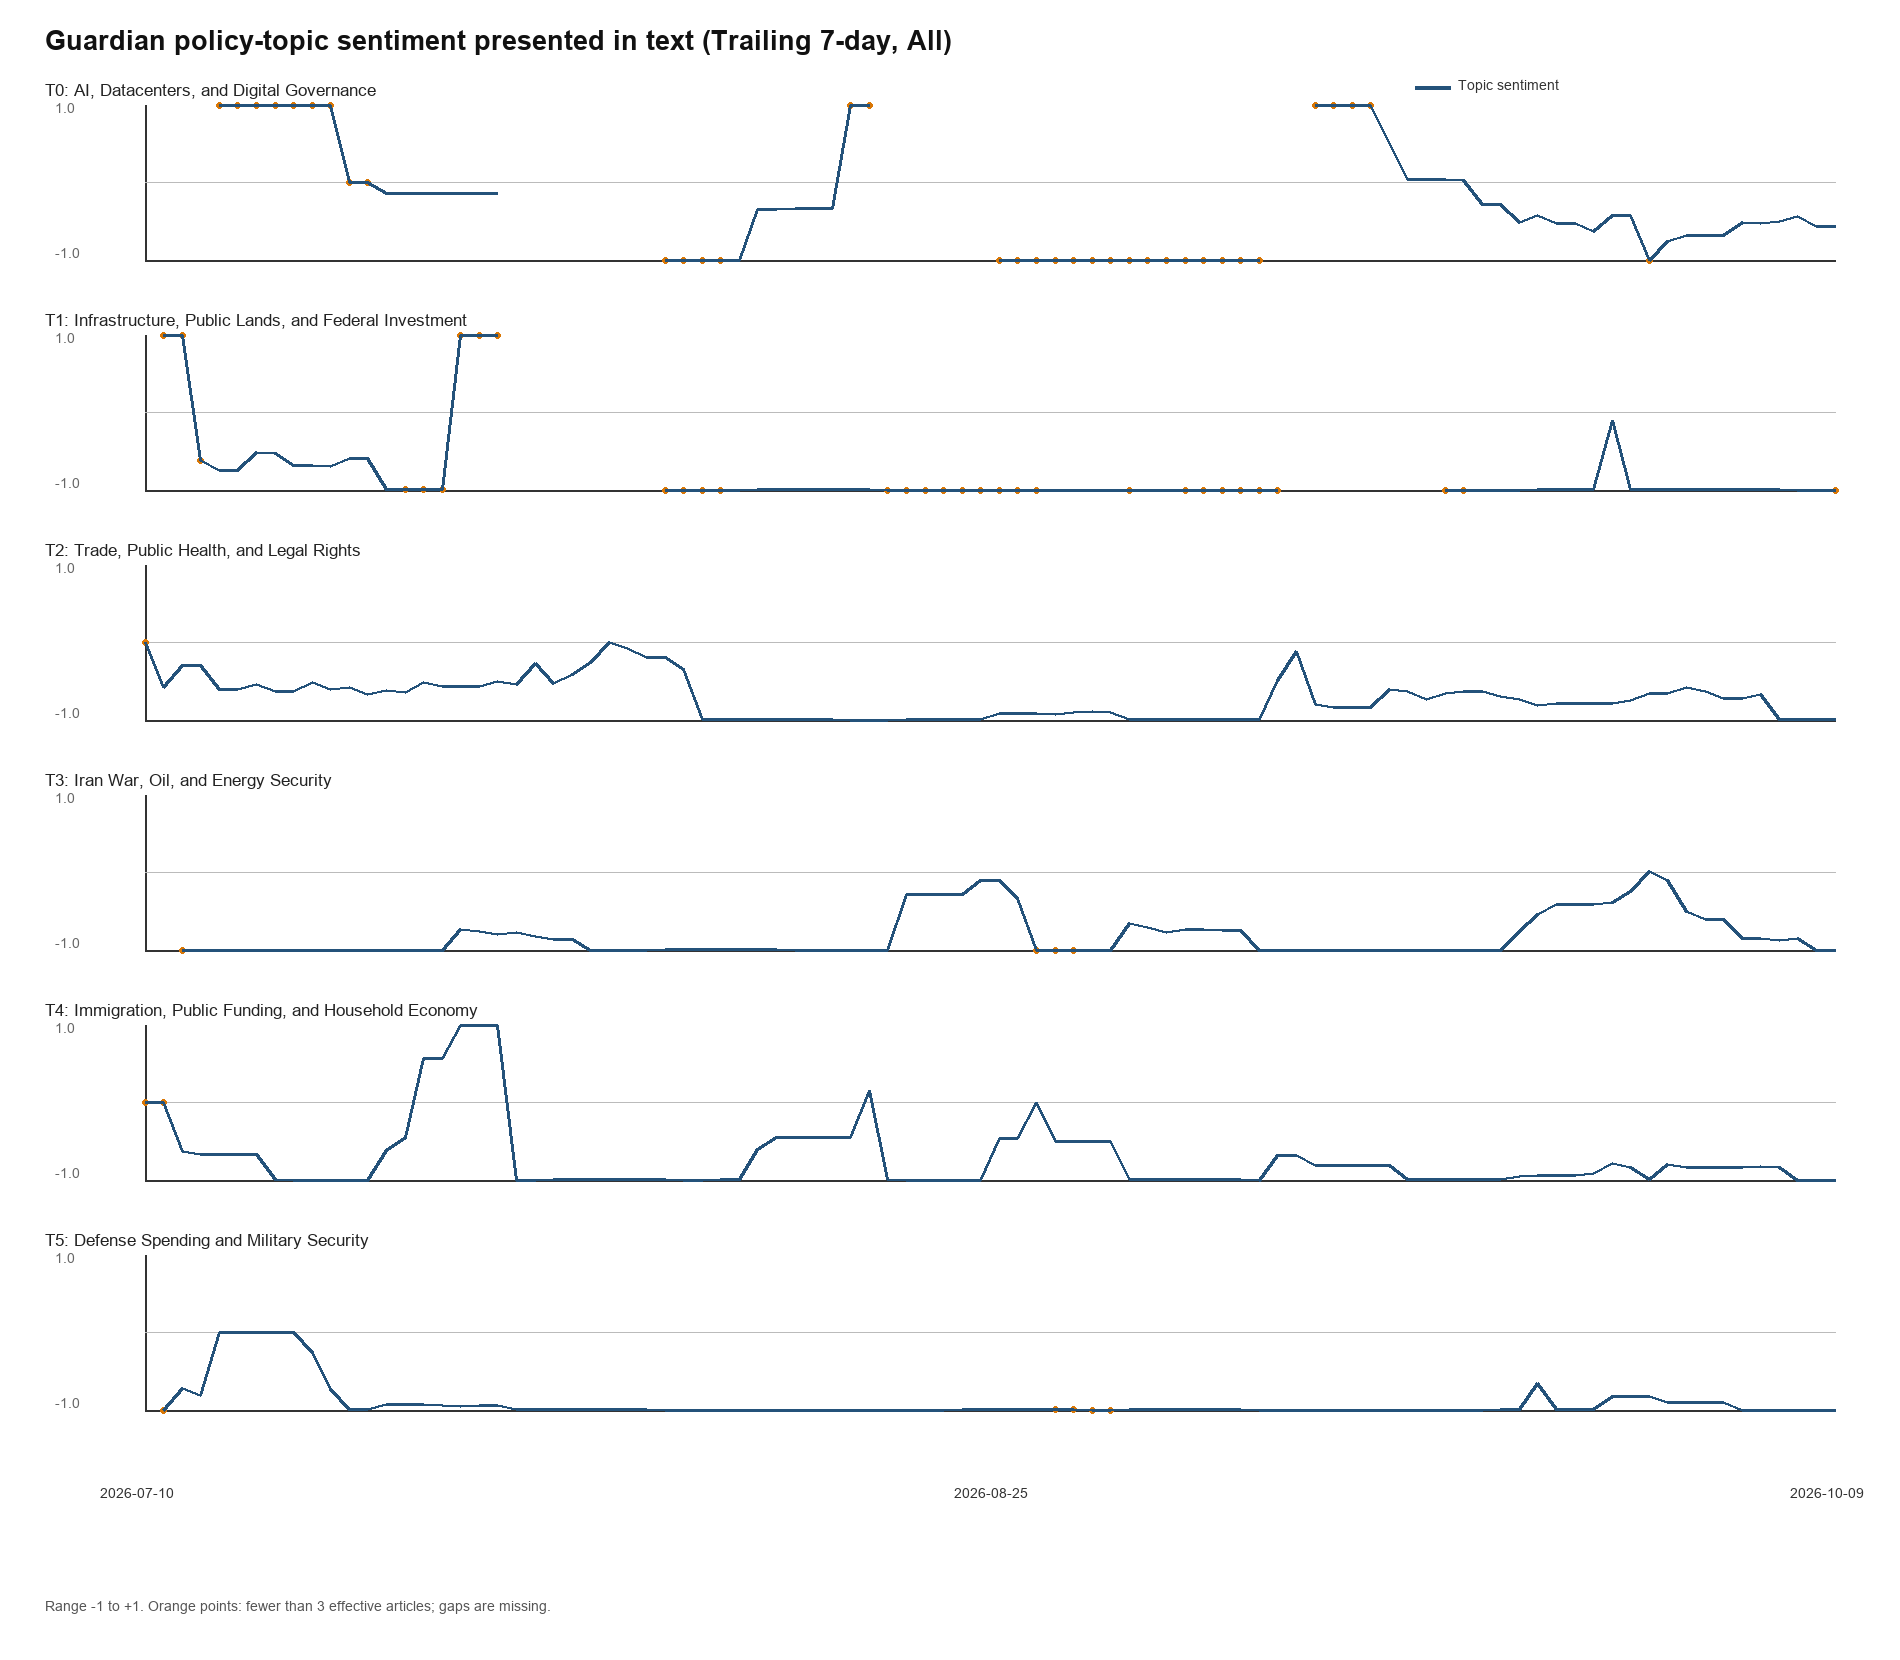

### Party

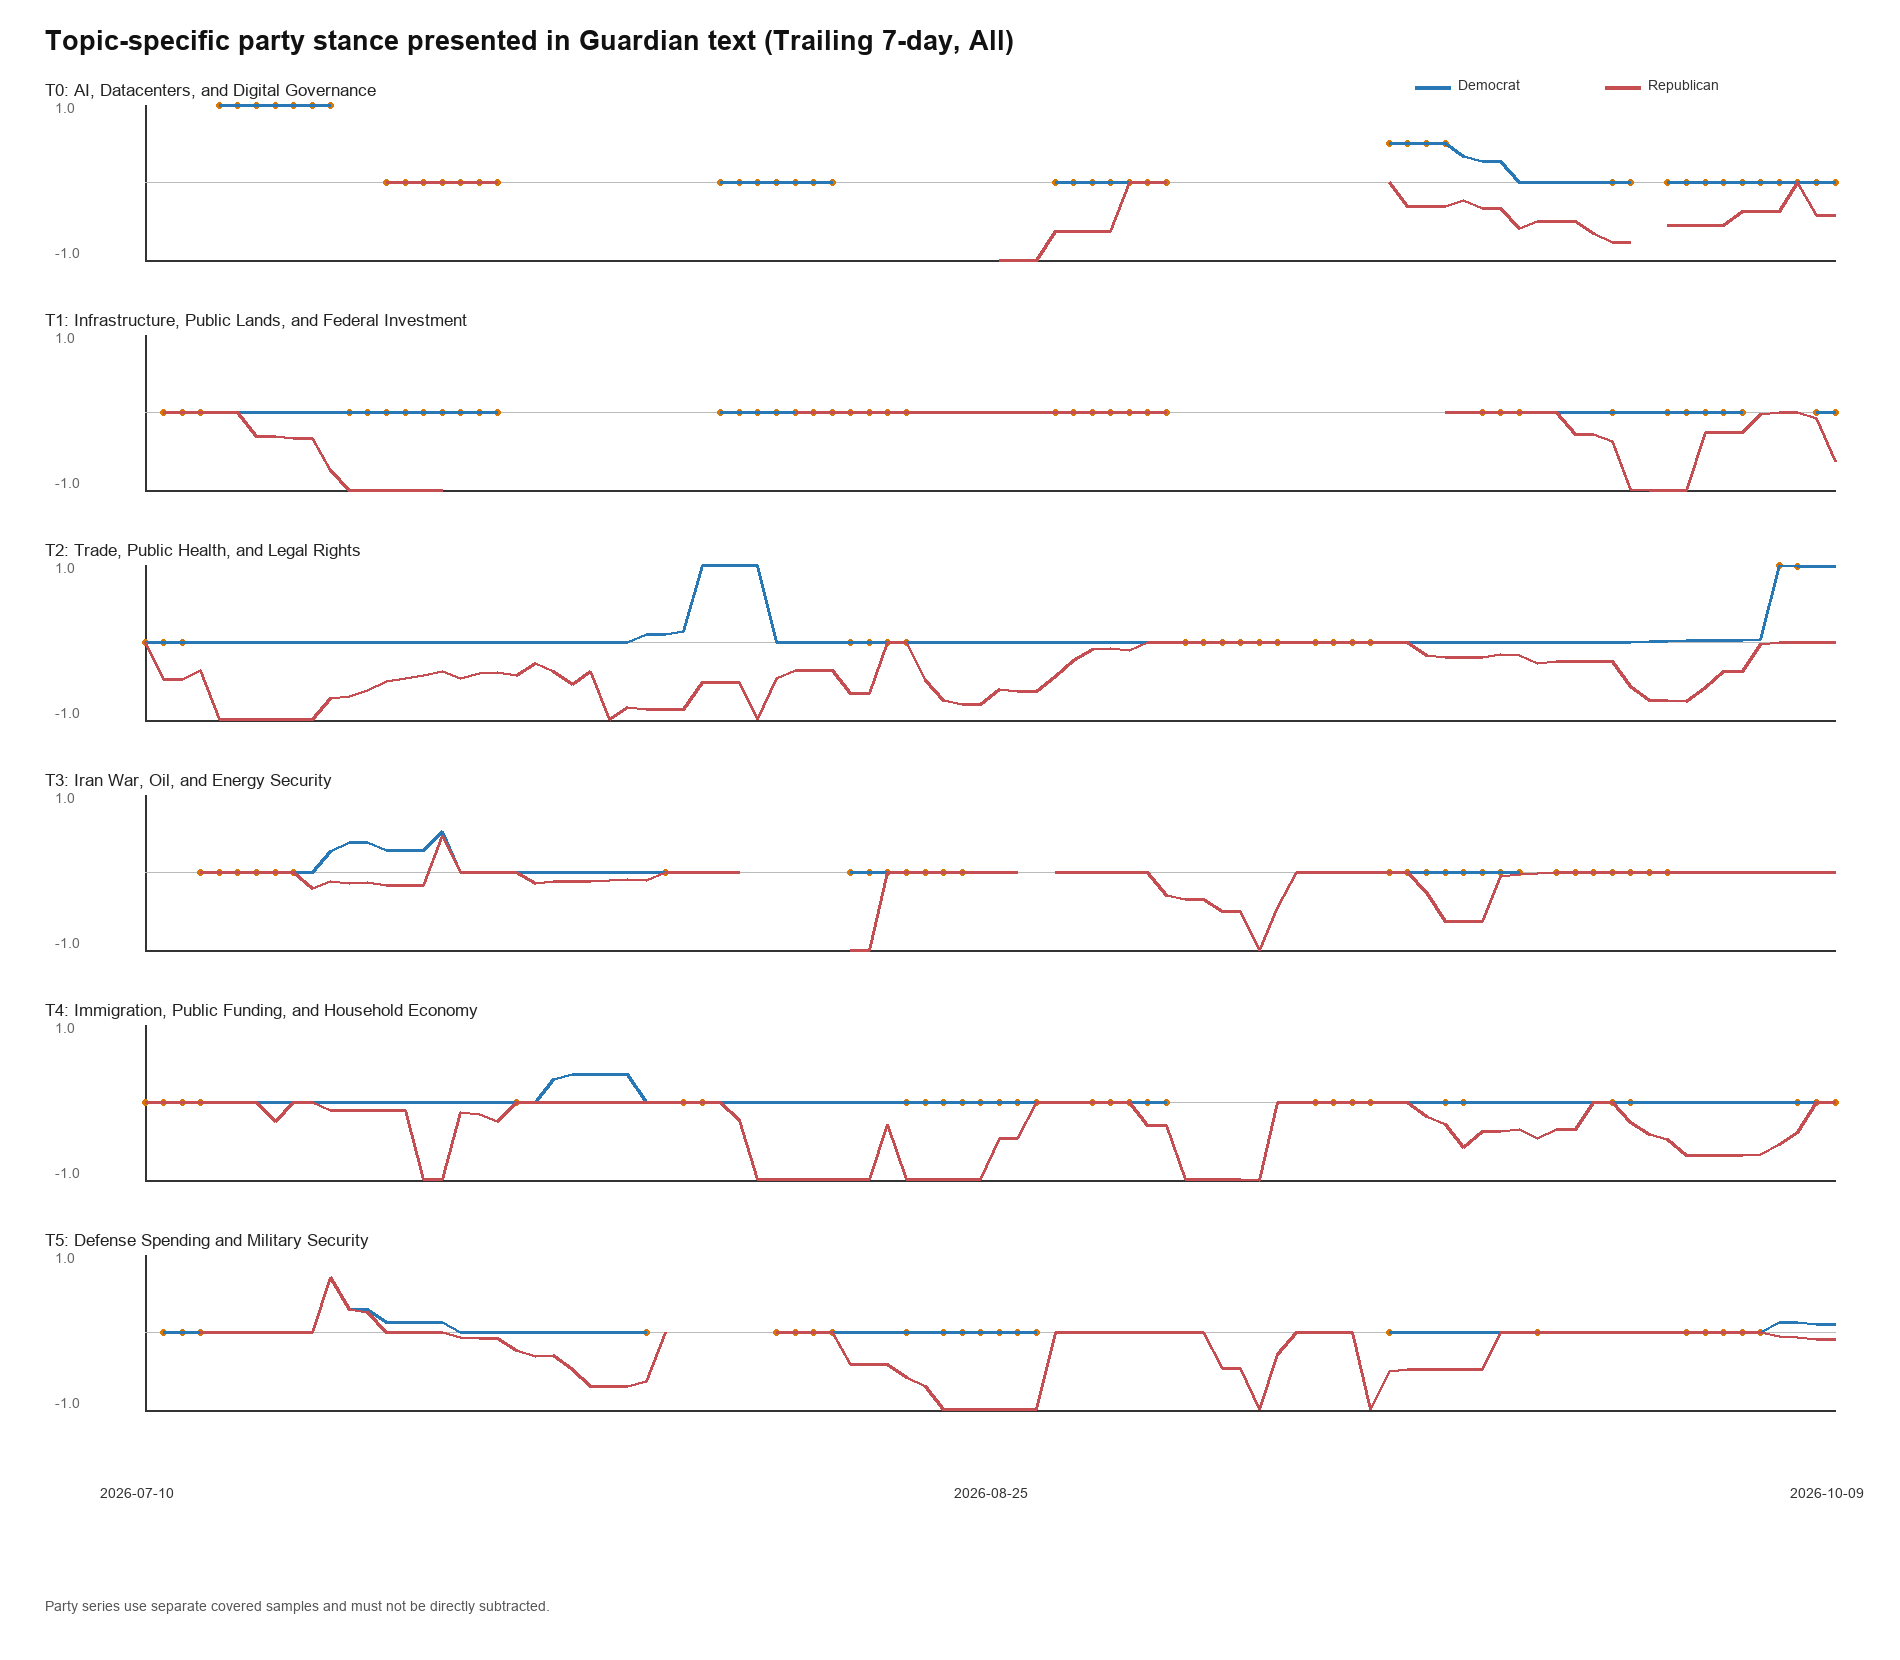

### Sample

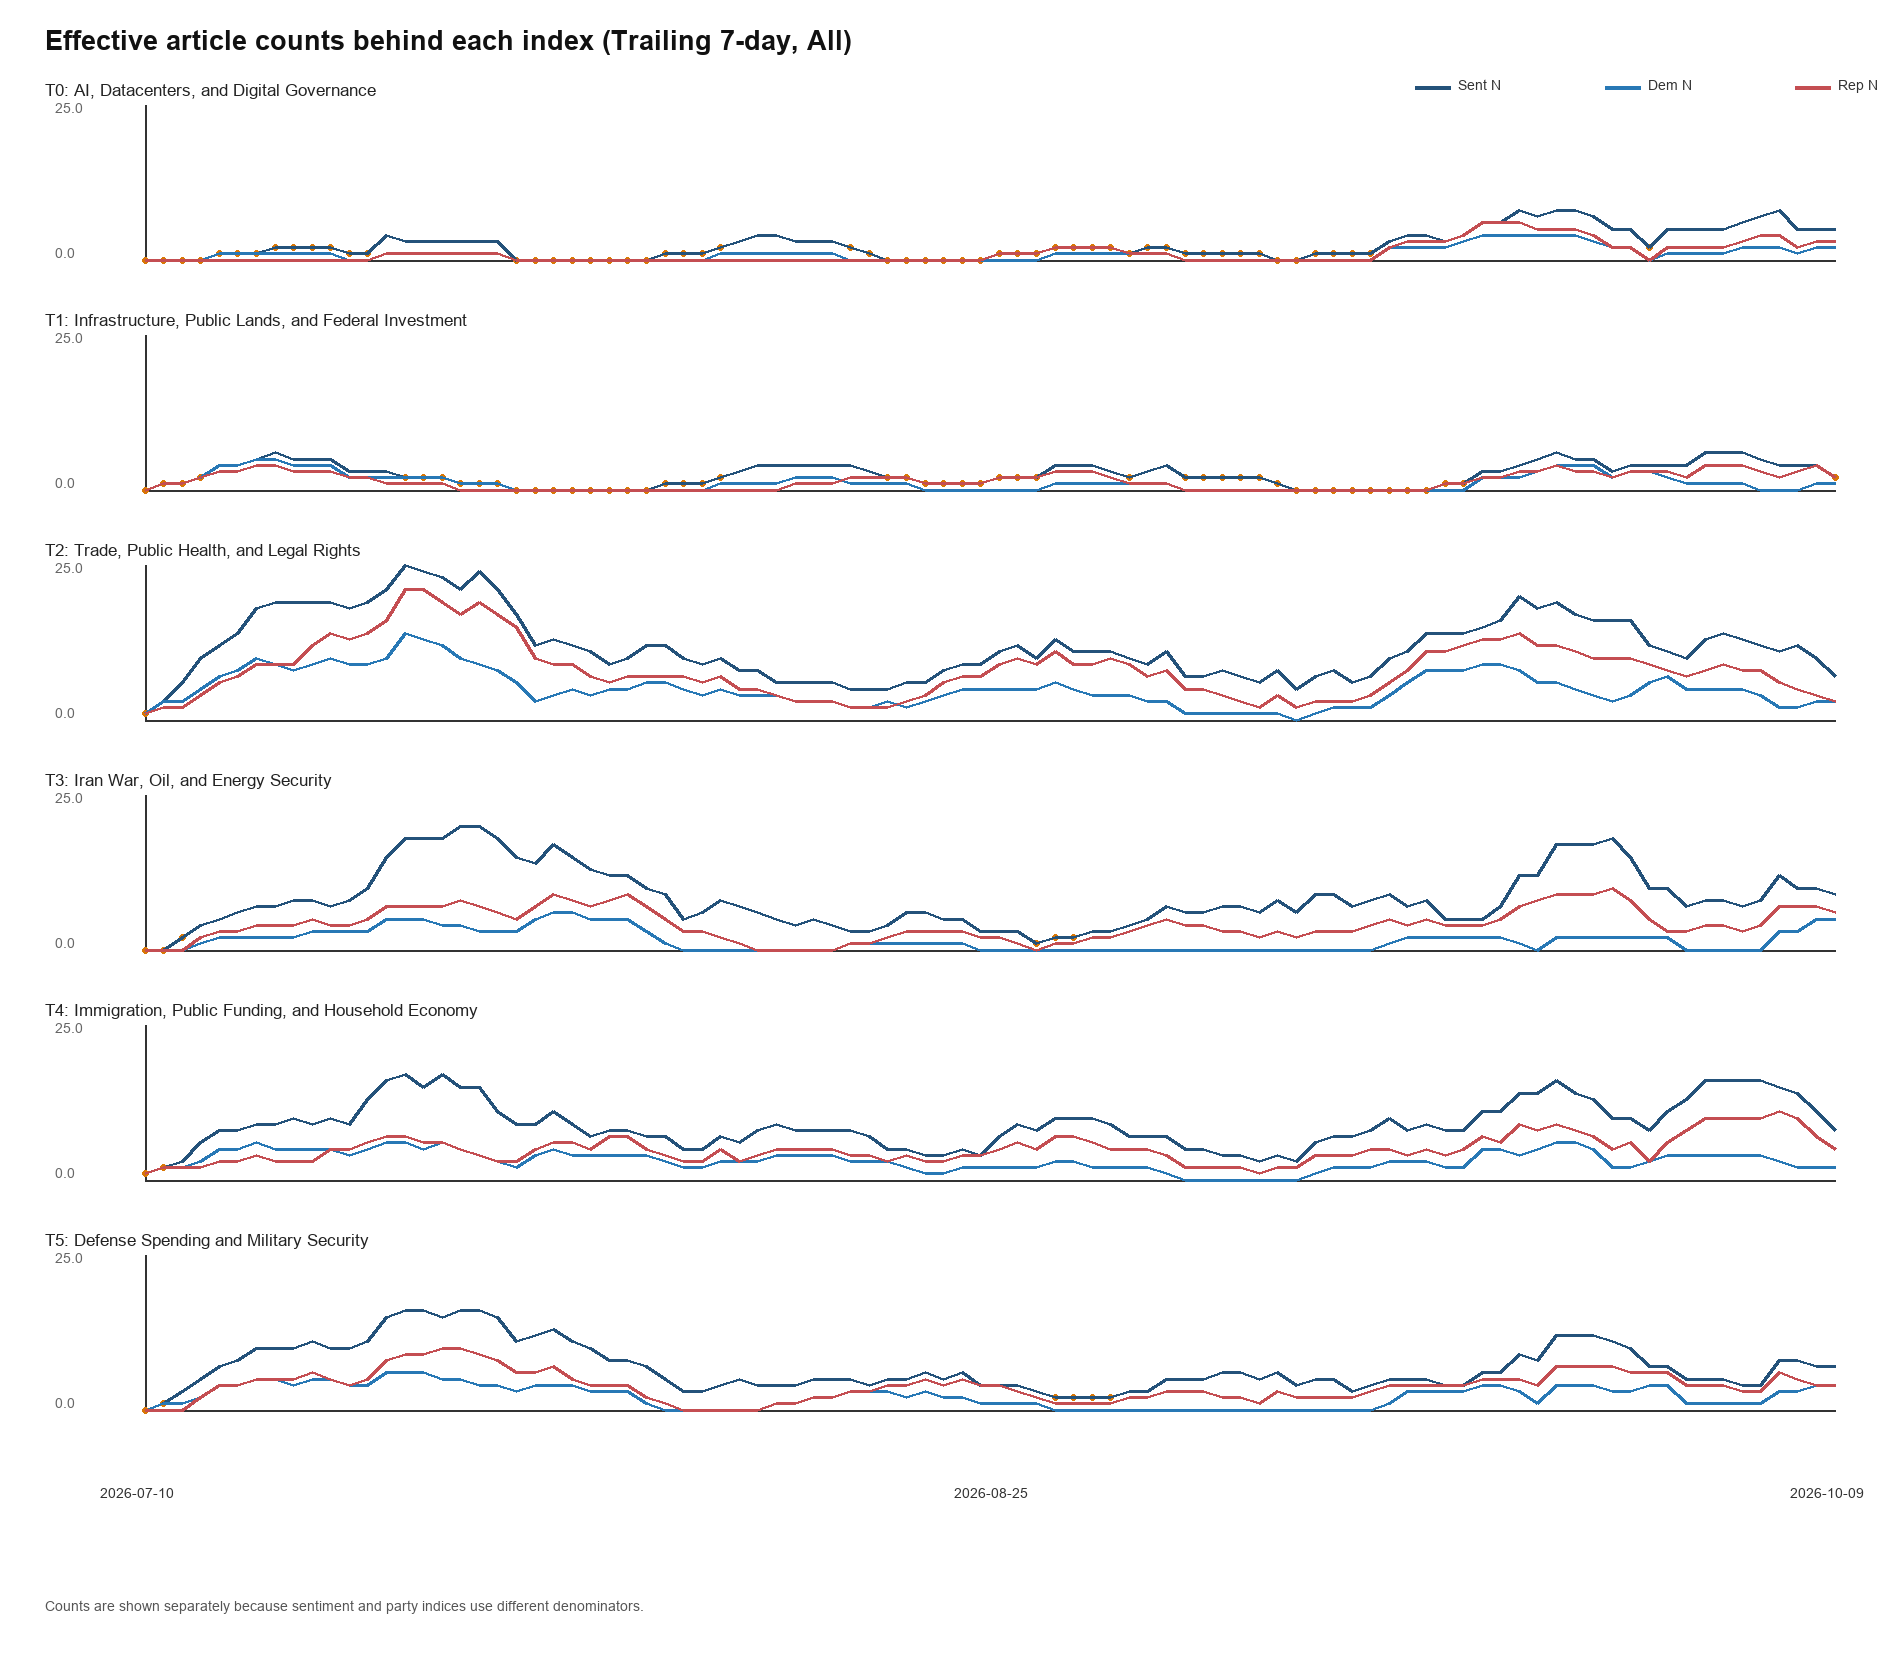

In [6]:
rolling_paths = draw_time_series('rolling', SECTION_GROUP)
show_outputs(rolling_paths)

## 周频时间序列

周频以纽约时间周一至周日为一周，直接合并该周文章后重新加权，不是对每日指数做简单平均。首周与末周是不完整周。

### Attention

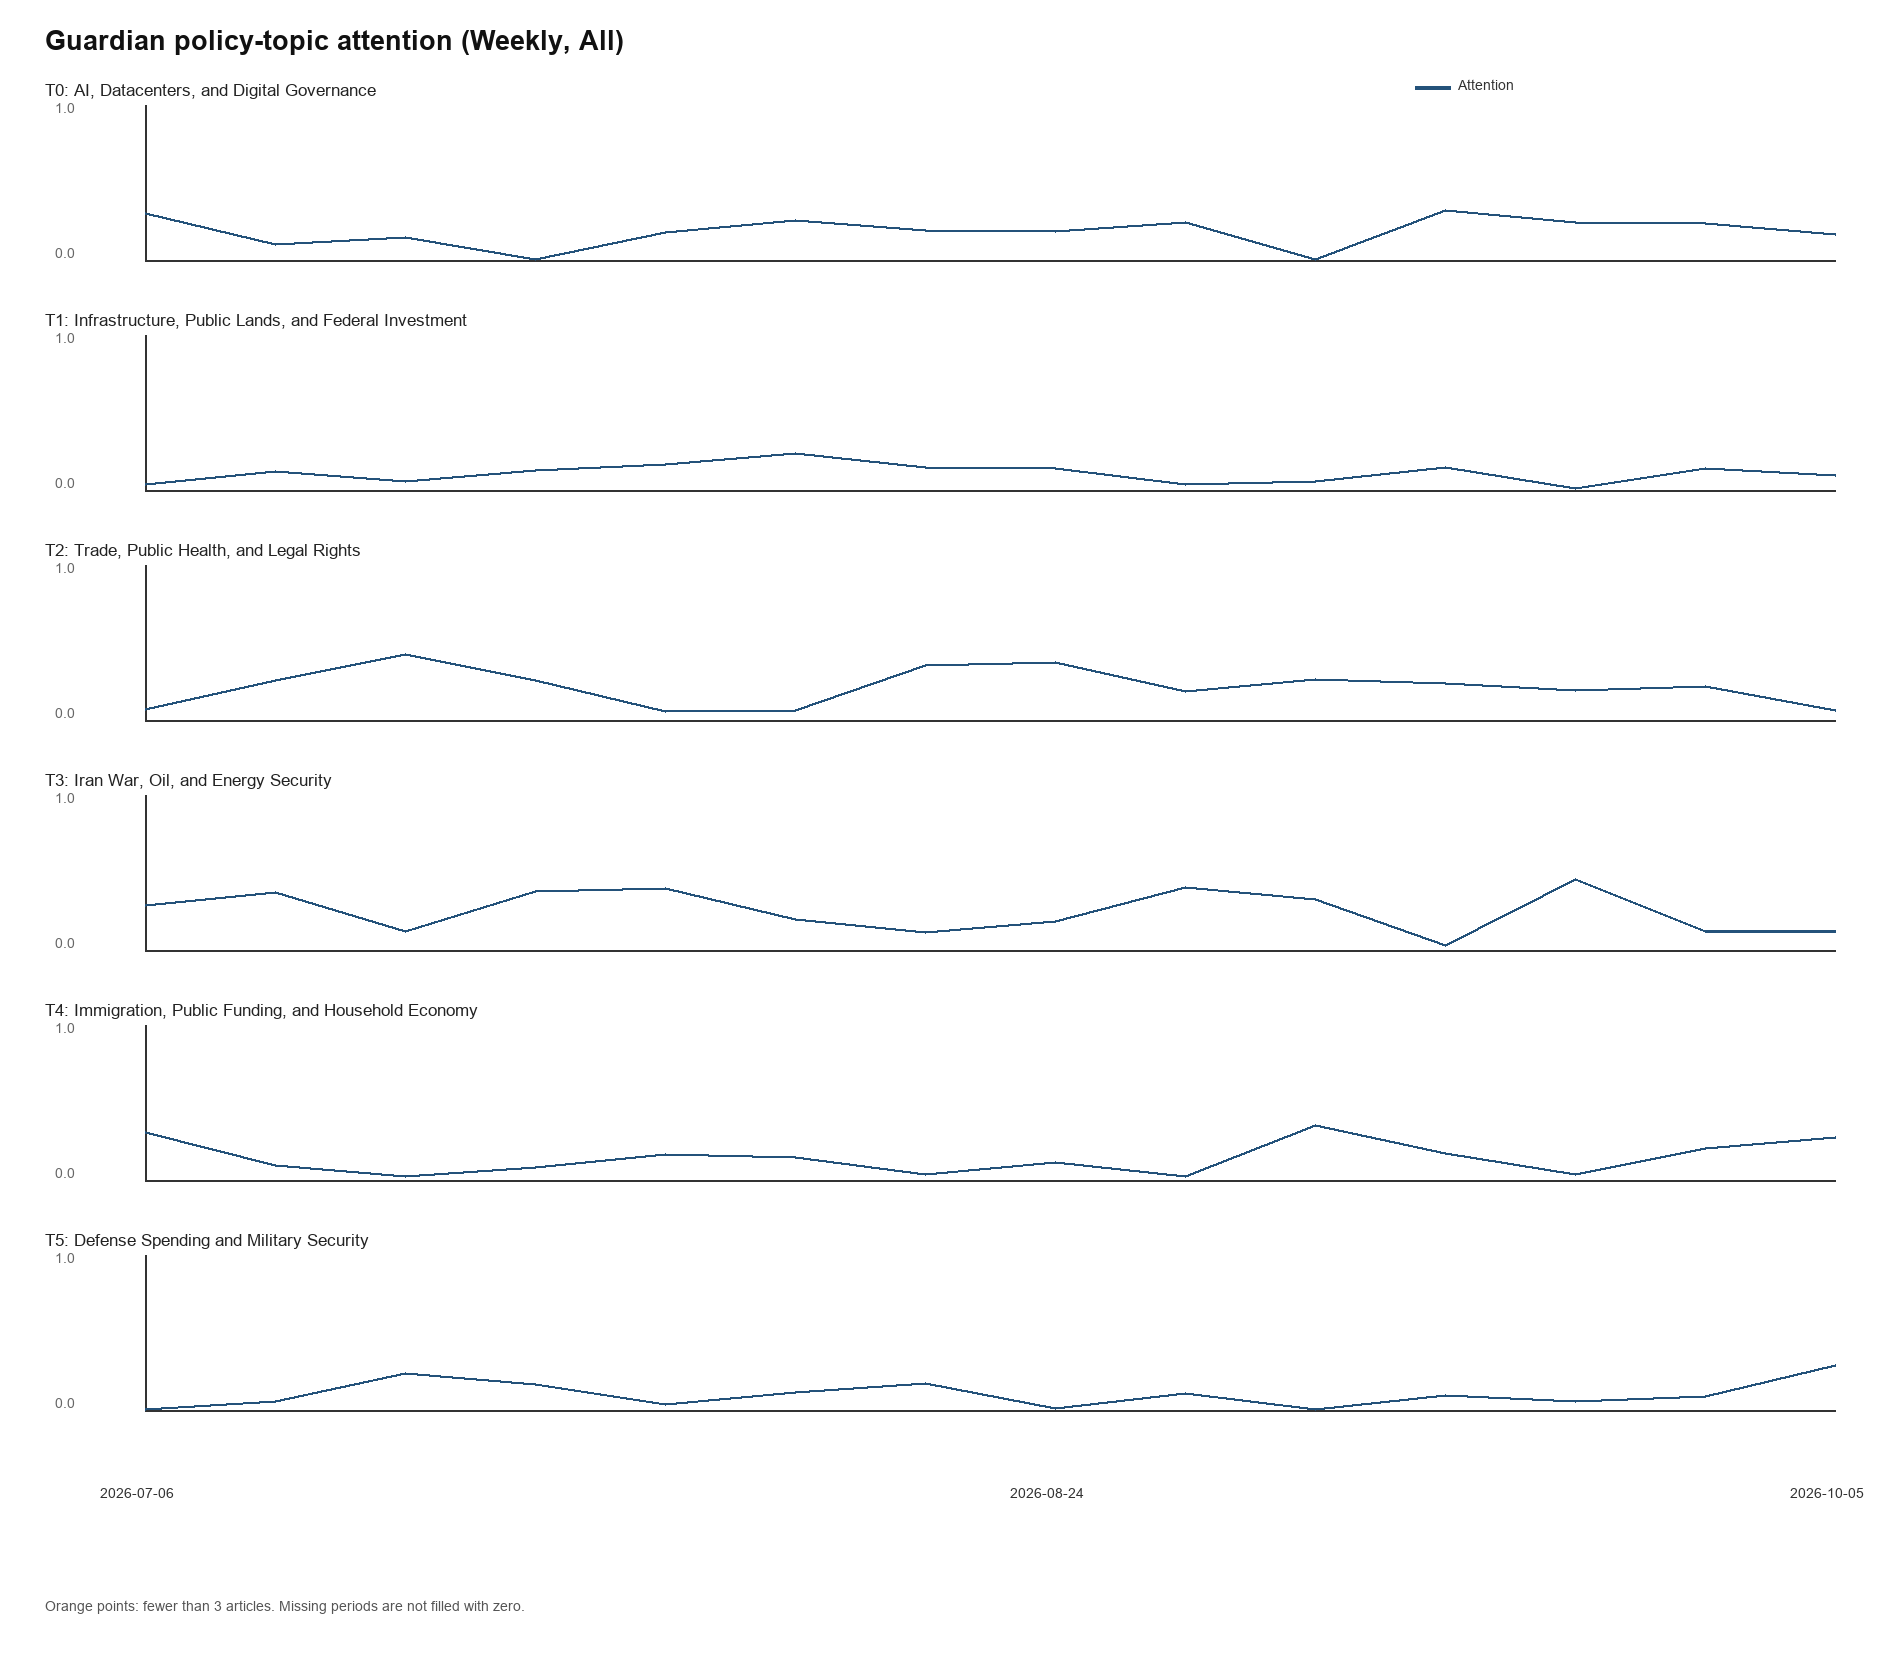

### Sentiment

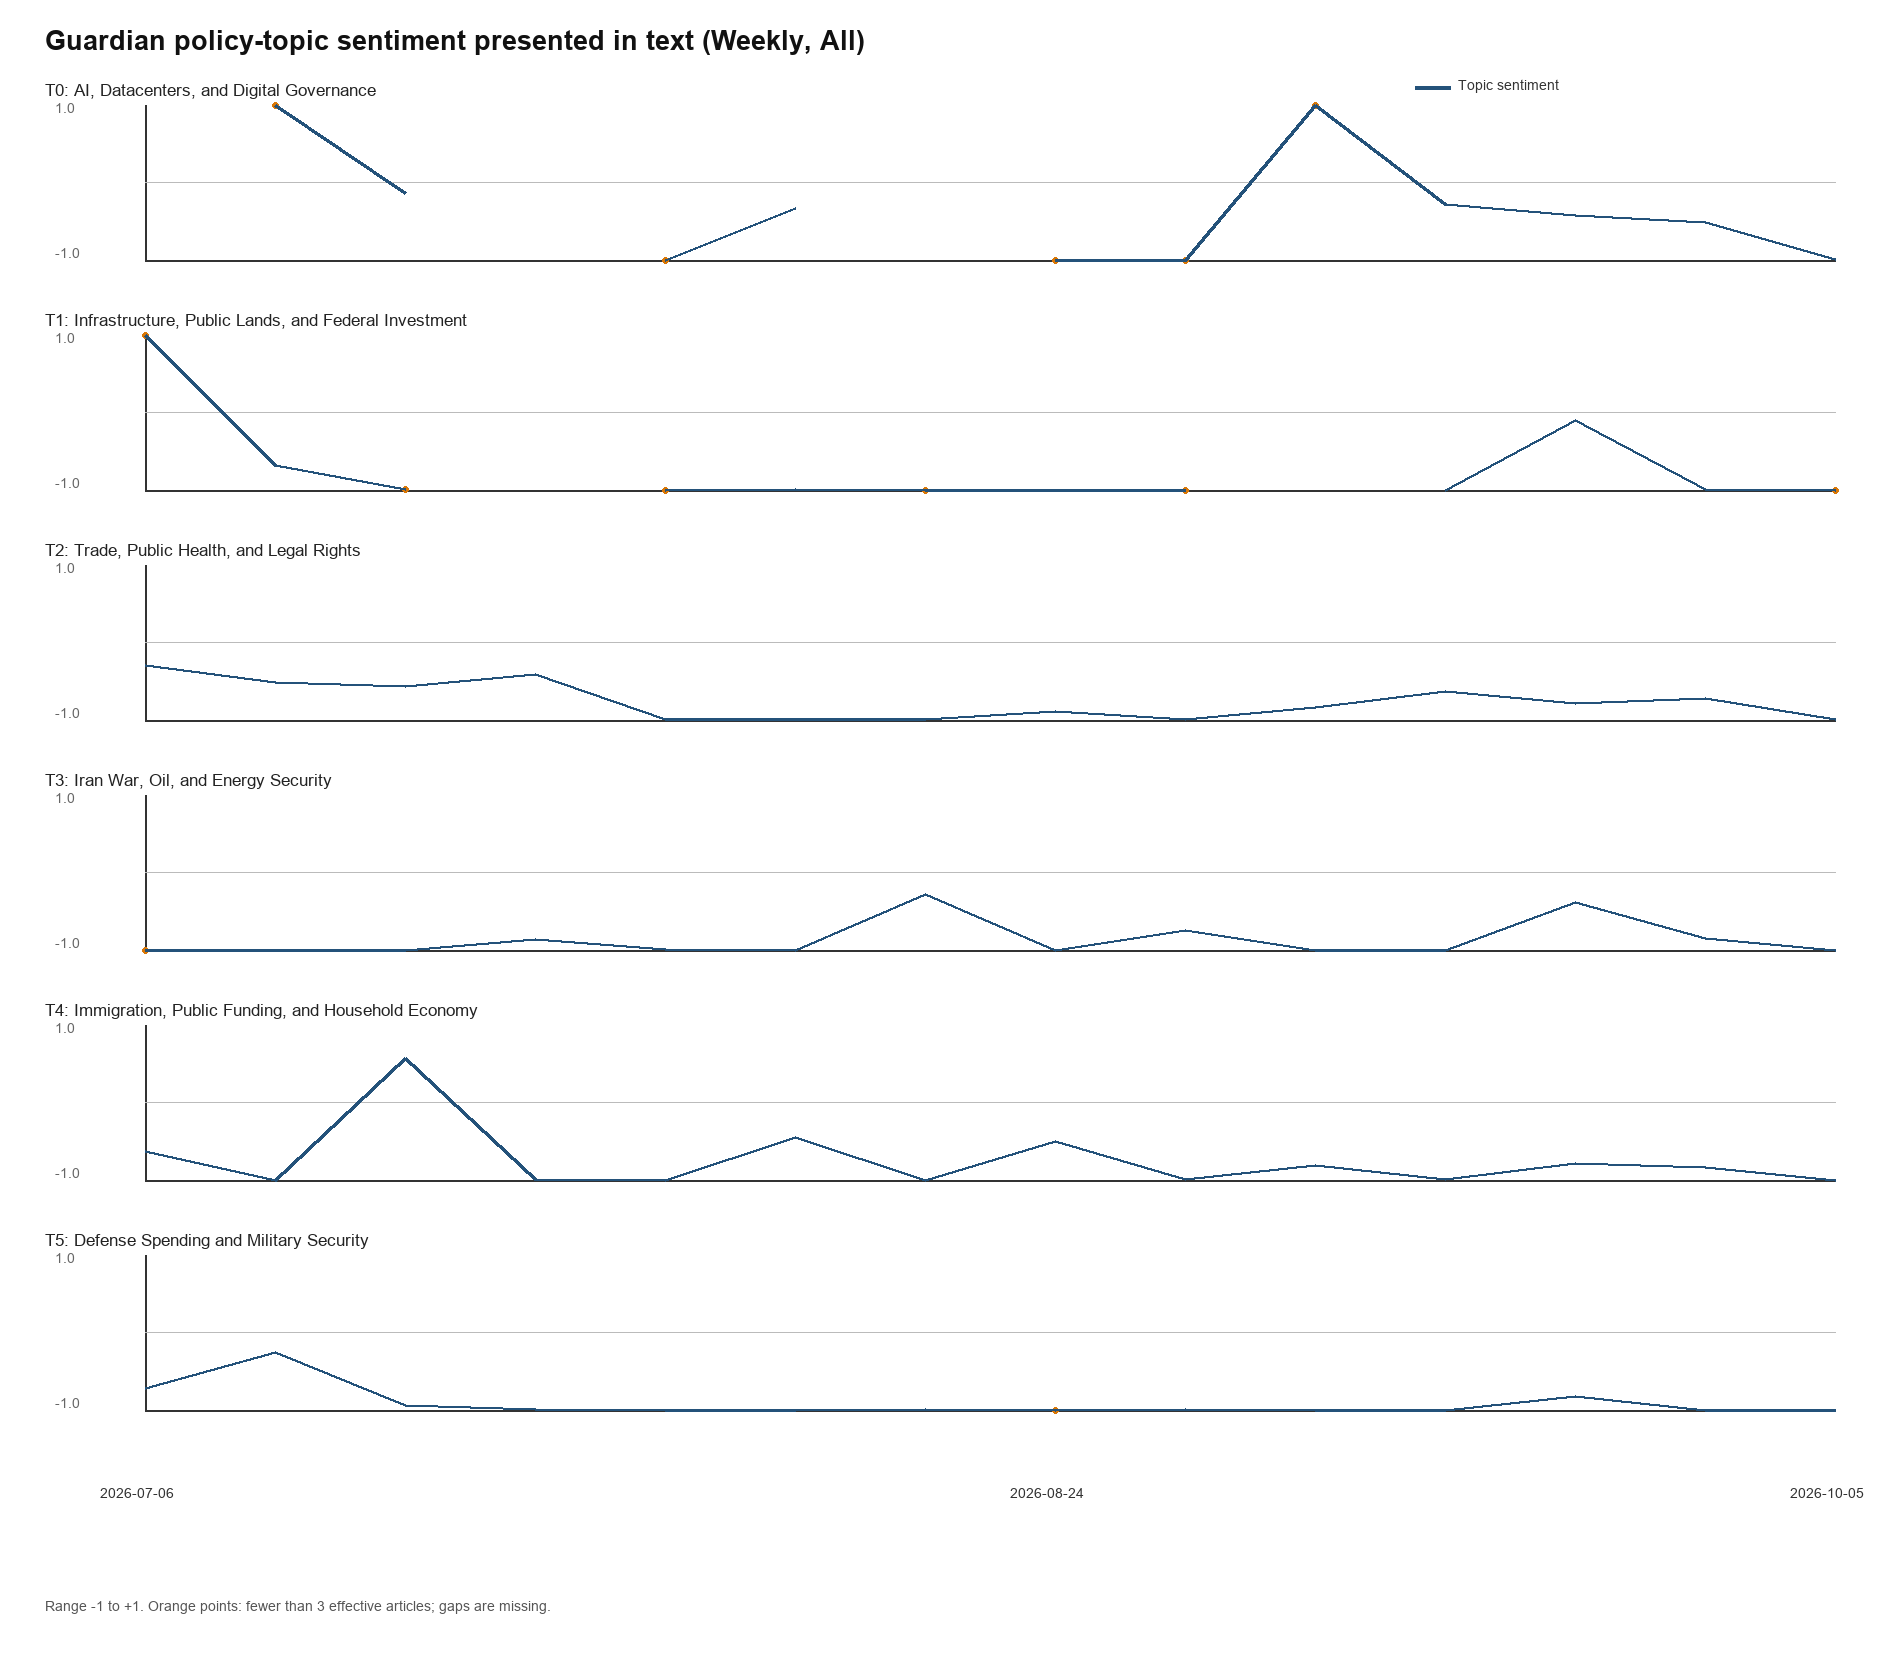

### Party

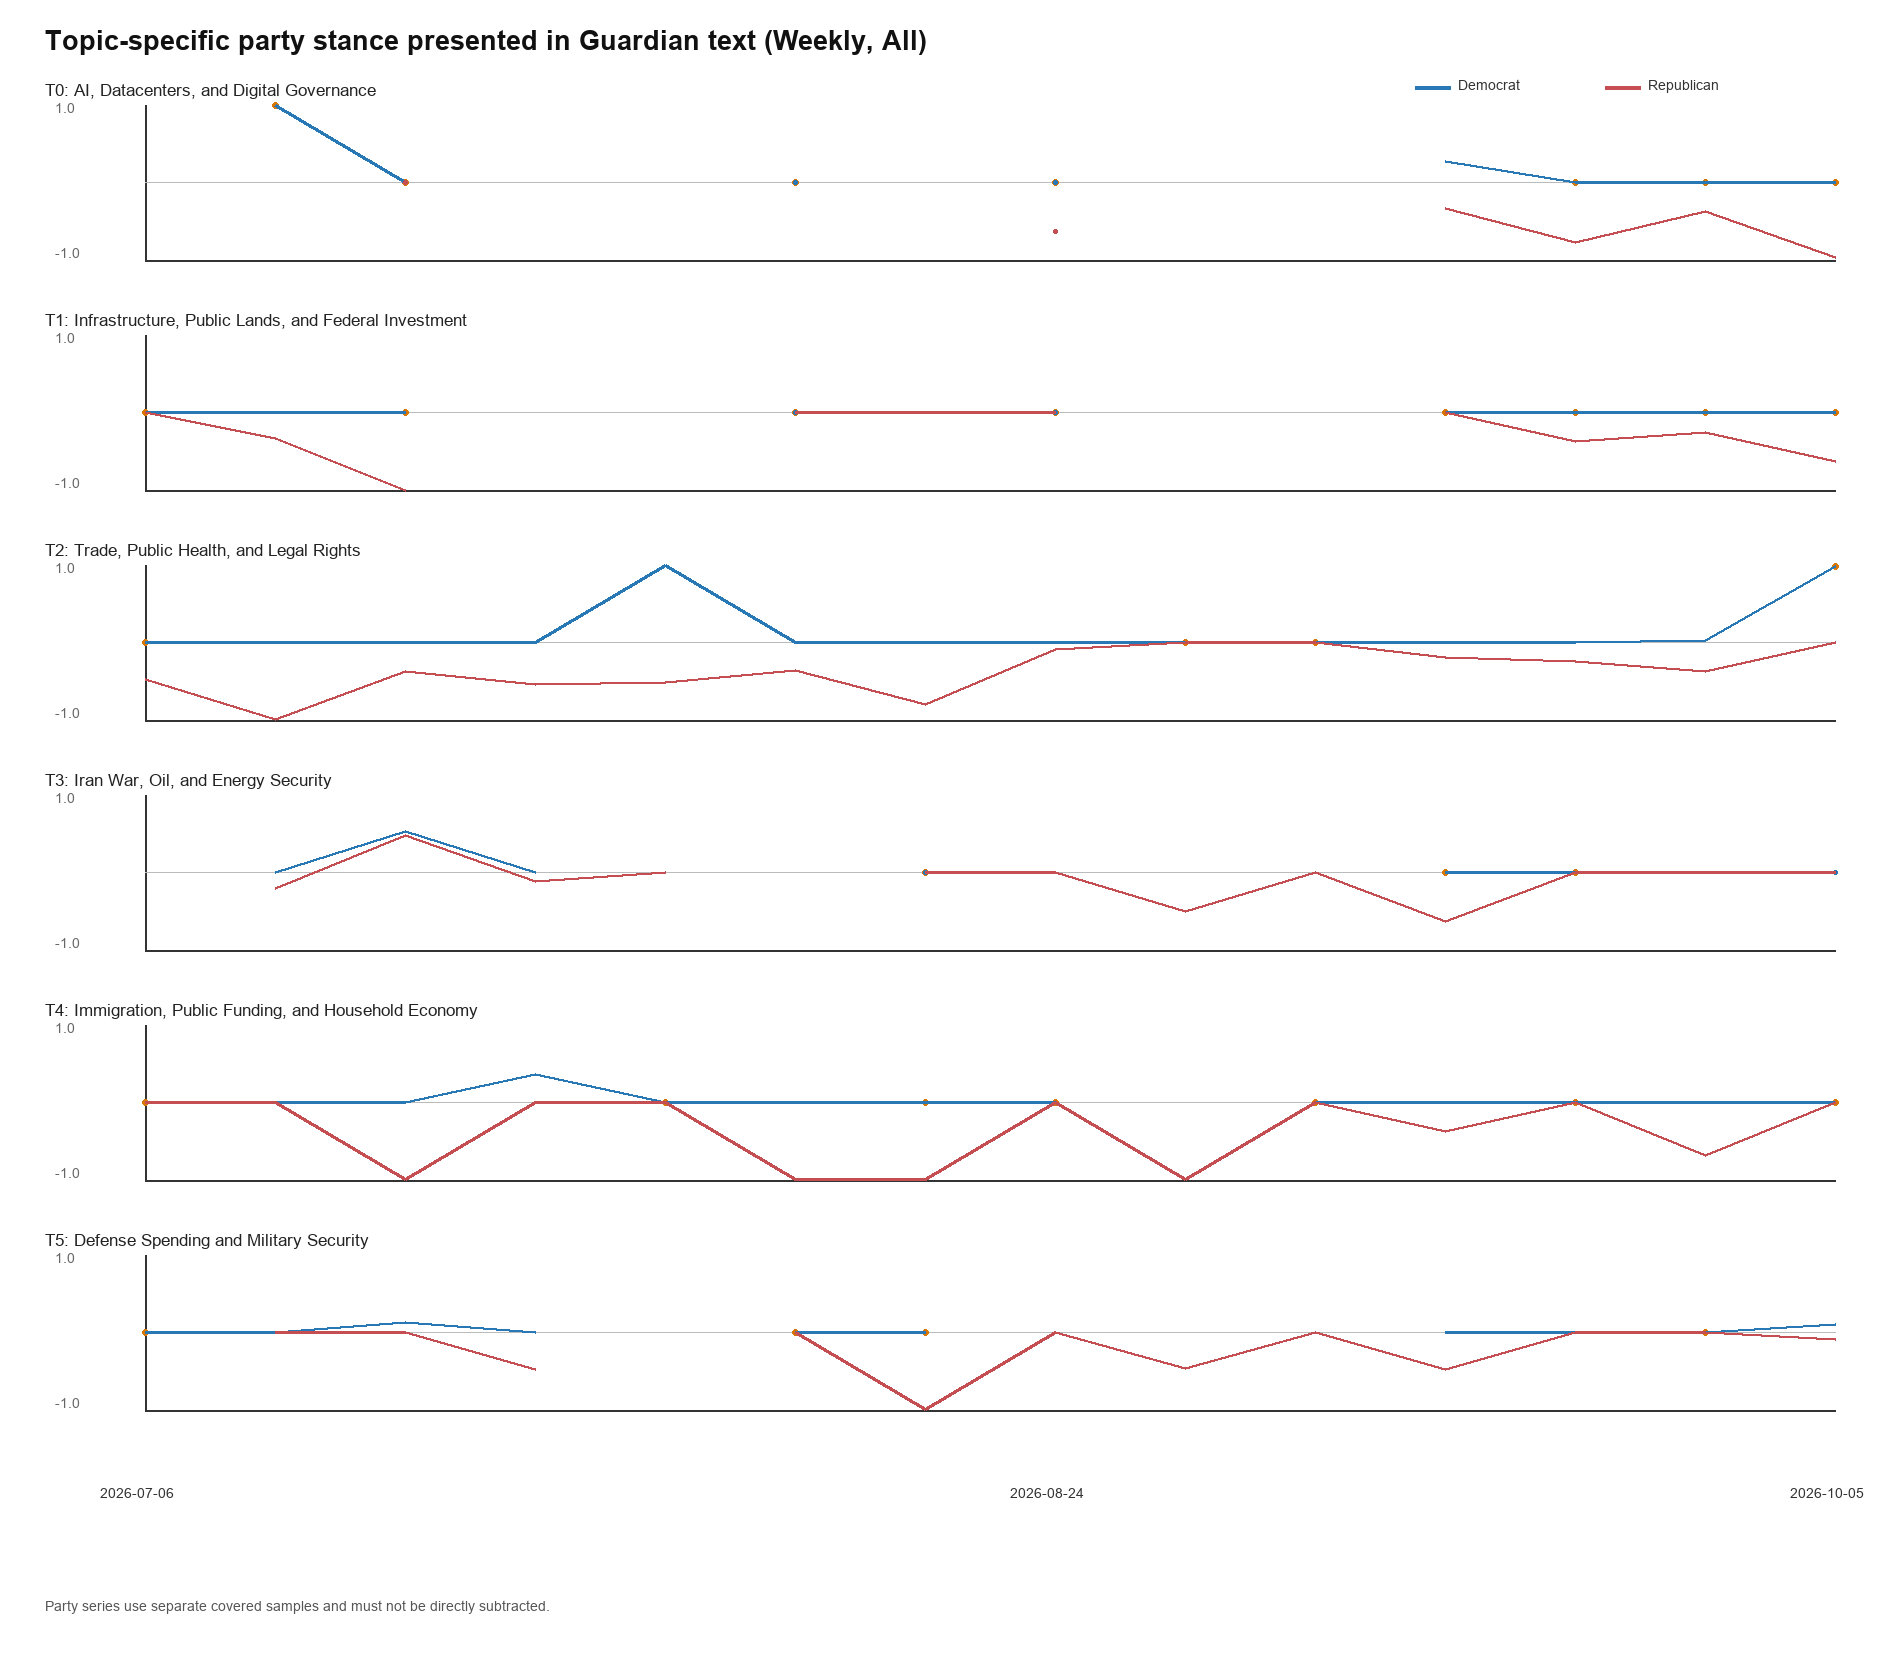

### Sample

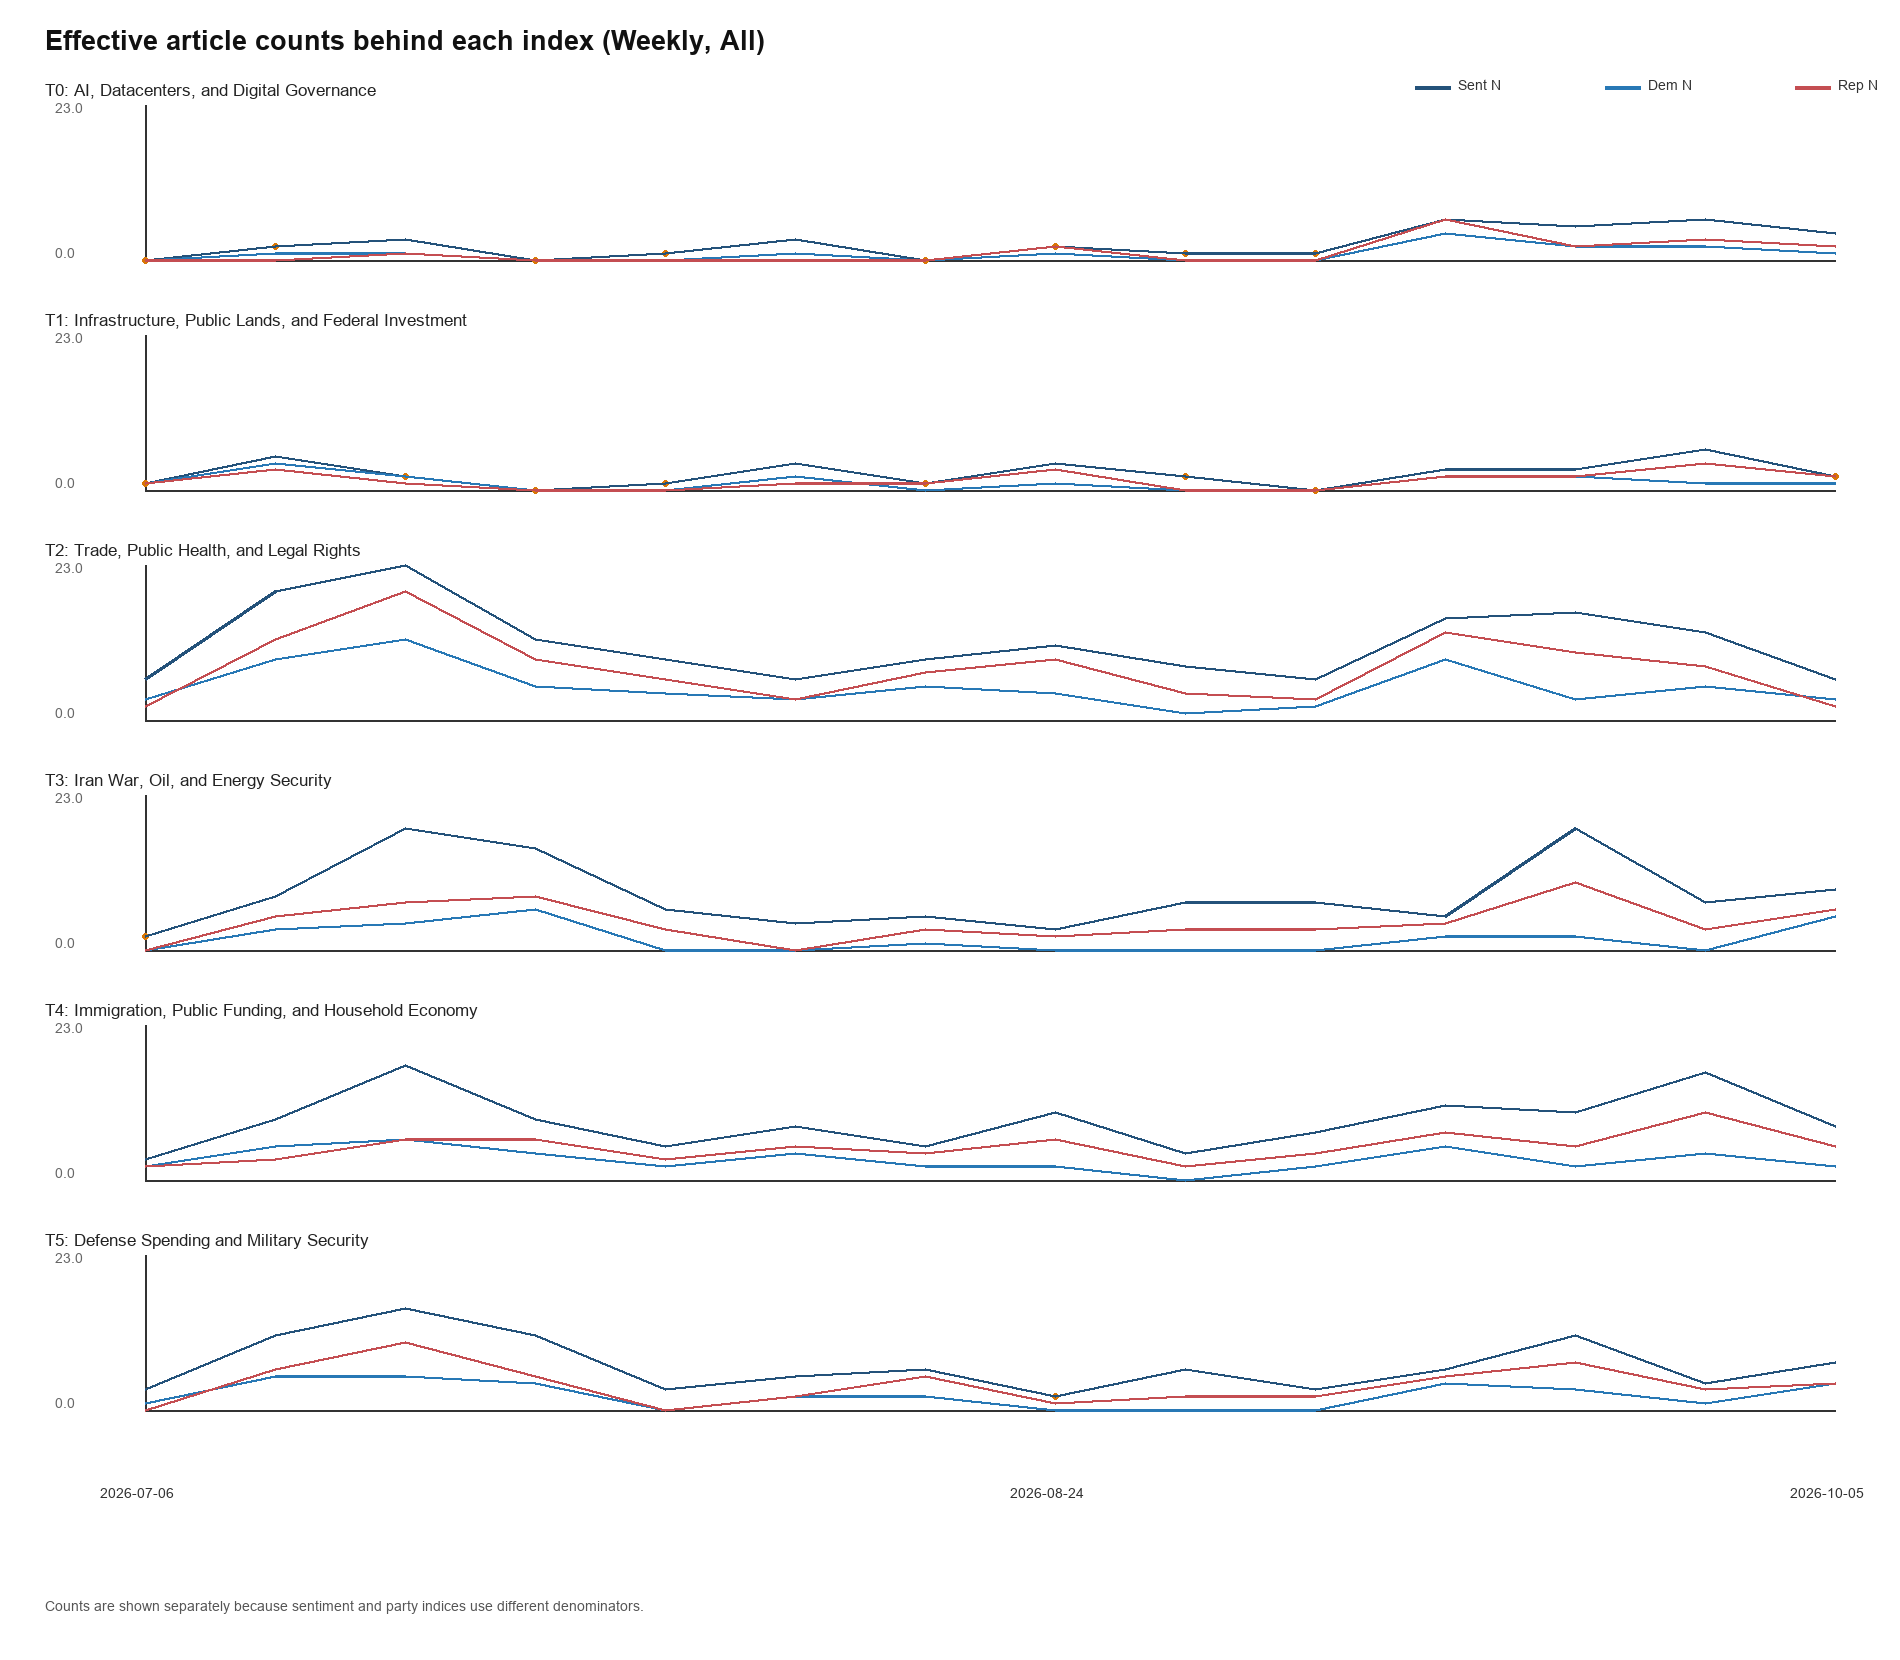

In [7]:
weekly_paths = draw_time_series('weekly', SECTION_GROUP)
show_outputs(weekly_paths)

## 解读说明

- 关注度来自全部有效 LDA 文章的主题概率。
- 议题情绪只纳入模型确认相关且情绪分非空的记录。
- 民主党和共和党态度使用各自的有效样本与权重，不能直接相减。
- 日频样本较稀疏，尤其是 T0 与 T1。趋势展示优先参考过去7天滚动或周频结果，并始终同时查看有效文章数。
- 若要比较报道与评论，将参数单元格中的 `SECTION_GROUP` 改为 `Opinion` 或 `Non-Opinion` 后重新运行全部单元格。